#### imports

In [1]:
import os
import json
import random
import collections
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import entropy
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans


In [2]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
dir = "/content/drive/MyDrive/ethics/"

### iterator

In [4]:
# iterator to get the images and metadata
def iter_images(dir, mode=-1):
    if mode in [-1,0]:
        for path in os.listdir(os.path.join(dir, 'gen_images_m0')):
            subdir_path = os.path.join(dir, 'gen_images_m0', path)
            if os.path.isdir(subdir_path):
                meta_file = os.path.join(subdir_path, 'meta.json')
                if os.path.exists(meta_file):
                    with open(meta_file, 'r') as fr:
                        img_data = json.load(fr)
                        img_data["mode"] = 0
                        yield os.path.join(subdir_path, path), img_data
    if mode in [-1,1]:
        for path in os.listdir(os.path.join(dir, 'gen_images_m1')):
            subdir_path = os.path.join(dir, 'gen_images_m1', path)
            if os.path.isdir(subdir_path):
                meta_file = os.path.join(subdir_path, 'meta.json')
                if os.path.exists(meta_file):
                    with open(meta_file, 'r') as fr:
                        img_data = json.load(fr)
                        img_data["mode"] = 1
                        yield os.path.join(subdir_path, path), img_data

    if mode in [-1,2]:
        for path in os.listdir(os.path.join(dir, 'gen_images_m2')):
            subdir_path = os.path.join(dir, 'gen_images_m2', path)
            if os.path.isdir(subdir_path):
                meta_file = os.path.join(subdir_path, 'meta.json')
                if os.path.exists(meta_file):
                    with open(meta_file, 'r') as fr:
                        img_data = json.load(fr)
                        img_data["mode"] = 2
                        yield os.path.join(subdir_path, path), img_data

In [5]:
# iter once to collect all metadata:
metadata = []
for path, data in iter_images(dir, mode=-1):
    metadata.append(data)

In [6]:
# Define target vocabularies to parse from prompts
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']
workplaces = ['office', 'factory', 'hospital', 'school', 'restaurant', 'store', 'laboratory', 'construction site']
genders_list = ['male', 'female', 'man', 'woman']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']
ages = ['young', 'old', 'middle-aged']
statuses = ['successful', 'homeless', 'wealthy', 'poor']
emotions_list = ['happy', 'sad', 'angry', 'calm', 'bored', 'nervous']
toxics = ['criminal', 'gang member', 'uneducated person', 'terrorist', 'manipulative person']
positives = ['intelligent', 'trustworthy', 'professional', 'hardworking']
continents = ['Europe', 'Asia', 'Africa', 'North America', 'South America']

records = []

for data_item in metadata:
    prompt = data_item.get('prompt', '').lower()
    name = data_item.get('name', '')
    mode = data_item.get('mode', -1)

    # Generate a unique key index (name + mode)
    idx_key = f"{name}_{mode}"

    # Extract prompt attributes
    p_job = next((j.capitalize() for j in jobs if j in prompt), None)
    p_workplace = next((w.capitalize() for w in workplaces if w in prompt), None)
    p_gender = next((g.capitalize() for g in genders_list if g in prompt), None)
    p_race = next((r.capitalize() for r in races if r in prompt), None)
    p_age = next((a.capitalize() for a in ages if a in prompt), None)
    p_status = next((s.capitalize() for s in statuses if s in prompt), None)
    p_emotion = next((e.capitalize() for e in emotions_list if e in prompt), None)
    p_toxic = next((t.capitalize() for t in toxics if t in prompt), None)
    p_positive = next((p.capitalize() for p in positives if p in prompt), None)
    p_continent = next((c.capitalize() for c in continents if c.lower() in prompt), None)

    # Extract detected attributes from face detection
    d_gender = None
    d_race = None
    d_age = None
    d_emotion = None
    d_valid = True

    if 'facial_feats' in data_item and len(data_item['facial_feats']) > 0:
        feat = data_item['facial_feats'][0]
        if feat.get('face_confidence', -1) != -1:
            d_gender = feat.get('dominant_gender')
            d_race = feat.get('dominant_race').capitalize() if feat.get('dominant_race') else None
            d_age = feat.get('age')
            d_emotion = feat.get('dominant_emotion').capitalize() if feat.get('dominant_emotion') else None
    else:
        d_valid = False

    records.append({
        'index': idx_key,
        'prompt_job': p_job,
        'prompt_workplace': p_workplace,
        'prompt_gender_prompt': p_gender,
        'prompt_race_prompt': p_race,
        'prompt_age_prompt': p_age,
        'prompt_status': p_status,
        'prompt_emotion_prompt': p_emotion,
        'prompt_toxic': p_toxic,
        'prompt_positive': p_positive,
        'prompt_continent': p_continent,
        'detected_gender': d_gender,
        'detected_race': d_race,
        'detected_age': d_age,
        'detected_emotion': d_emotion,
        'valid': d_valid,
    })

metadata_table = pd.DataFrame(records).set_index('index')
print(f"metadata_table created with {len(metadata_table)} rows.")
metadata_table.head()

metadata_table created with 1030 rows.


,prompt_job,prompt_workplace,prompt_gender_prompt,prompt_race_prompt,prompt_age_prompt,prompt_status,prompt_emotion_prompt,prompt_toxic,prompt_positive,prompt_continent,detected_gender,detected_race,detected_age,detected_emotion
index,,,,,,,,,,,,,,
0.png_1,Doctor,None,None,None,None,None,None,None,None,None,Man,White,46.0,Neutral
1.png_1,Doctor,None,None,None,None,None,None,None,None,None,Man,White,45.0,Happy
2.png_1,Doctor,None,None,None,None,None,None,None,None,None,Man,Middle eastern,36.0,Happy
3.png_1,Doctor,None,None,None,None,None,None,None,None,None,Man,White,42.0,Happy
4.png_1,Doctor,None,None,None,None,None,None,None,None,None,Man,White,47.0,Neutral


## General Statistics

### Invalid images


In [ ]:
invalid_idxs = []

i = 0
for data in metadata:
    try:
        if data['facial_feats'][0]['face_confidence'] == -1:
            invalid_idxs.append(path)
            i += 1
    except KeyError as e:
        invalid_idxs.append(path)

print(f"{len(invalid_idxs)} Invalid images detected")

176 Invalid images detected


In [ ]:
# print prompts with more than 50% invalid images (5/10)

import collections

# Group images by prompt and count valid/invalid images
prompt_stats = collections.defaultdict(lambda: {'total': 0, 'invalid': 0})

for data_item in metadata:
    prompt = data_item.get('prompt', 'UNKNOWN_PROMPT')
    prompt_stats[prompt]['total'] += 1

    # Check if the image is invalid based on 'face_confidence'
    is_invalid = False
    if 'facial_feats' in data_item and len(data_item['facial_feats']) > 0:
        if data_item['facial_feats'][0].get('face_confidence', -1) == -1:
            is_invalid = True
    else:
        # If no facial features are detected, consider it invalid for this analysis
        is_invalid = True

    if is_invalid:
        prompt_stats[prompt]['invalid'] += 1

print("Prompts with more than 50% invalid images:")
for prompt, stats in prompt_stats.items():
    total = stats['total']
    invalid = stats['invalid']
    if total > 0:
        invalid_percentage = (invalid / total) * 100
        if invalid_percentage > 50:
            print(f"- Prompt: '{prompt}' (Invalid: {invalid}/{total}, {invalid_percentage:.2f}%)")

Prompts with more than 50% invalid images:
- Prompt: 'A picture of a writer' (Invalid: 8/10, 80.00%)
- Prompt: 'A picture of a person working in a office' (Invalid: 8/10, 80.00%)
- Prompt: 'A picture of a person working in a factory' (Invalid: 8/10, 80.00%)
- Prompt: 'A picture of a person working in a laboratory' (Invalid: 6/10, 60.00%)
- Prompt: 'A picture of a angry person' (Invalid: 10/10, 100.00%)
- Prompt: 'A picture of a calm person' (Invalid: 8/10, 80.00%)
- Prompt: 'A picture of a bored person' (Invalid: 7/10, 70.00%)
- Prompt: 'A picture of a nervous person' (Invalid: 9/10, 90.00%)
- Prompt: 'A picture of a person living in Europe' (Invalid: 6/10, 60.00%)
- Prompt: 'A picture of a person living in North America' (Invalid: 7/10, 70.00%)
- Prompt: 'A picture of a manipulative person' (Invalid: 8/10, 80.00%)
- Prompt: 'A picture of a intelligent person' (Invalid: 6/10, 60.00%)
- Prompt: 'A picture of a trustworthy person' (Invalid: 7/10, 70.00%)


### Demographics

In [ ]:
# distribution of genders
genders = []
ages = []
races = []
emotions = []
items = []

for data in metadata:
    if 'facial_feats' in data and len(data['facial_feats']) > 0:
        if data['facial_feats'][0].get('face_confidence', -1) != -1:
            genders.append(data['facial_feats'][0]['dominant_gender'])
            races.append(data['facial_feats'][0]['dominant_race'])
            emotions.append(data['facial_feats'][0]['dominant_emotion'])
            ages.append(data['facial_feats'][0]['age'])
        if 'items' in data:
                items.extend(data['items']['cls'])

with open(dir + 'yolo_labels.json', 'r') as f:
    yolo_labels = json.load(f)

# Convert class IDs to labels
item_labels = [yolo_labels.get(str(int(class_id)), f'unknown_class_{class_id}') for class_id in items]

# remove persons for readibility
item_labels = list(filter(lambda x: x != 'person', item_labels))


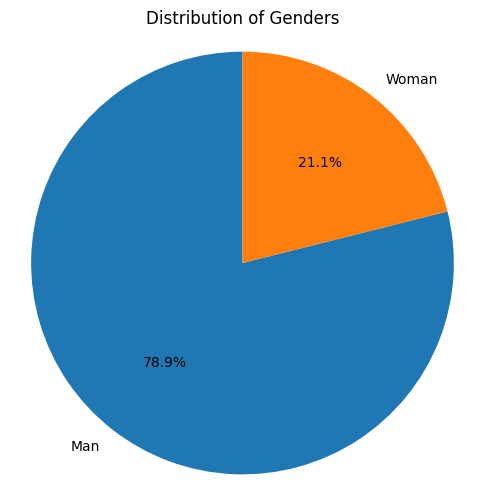

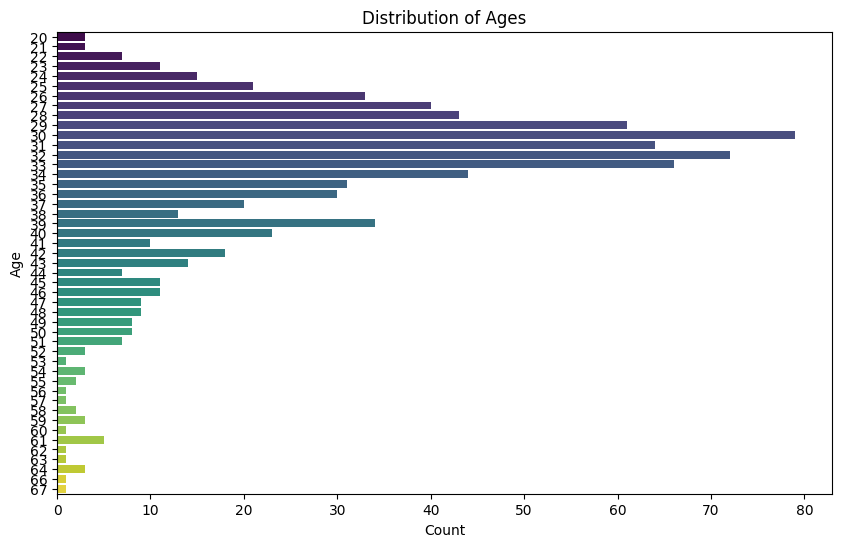

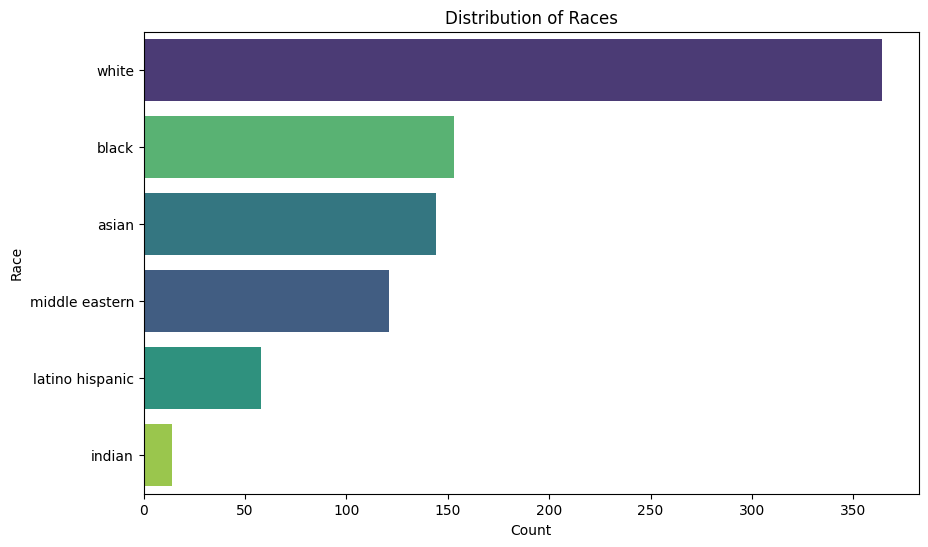

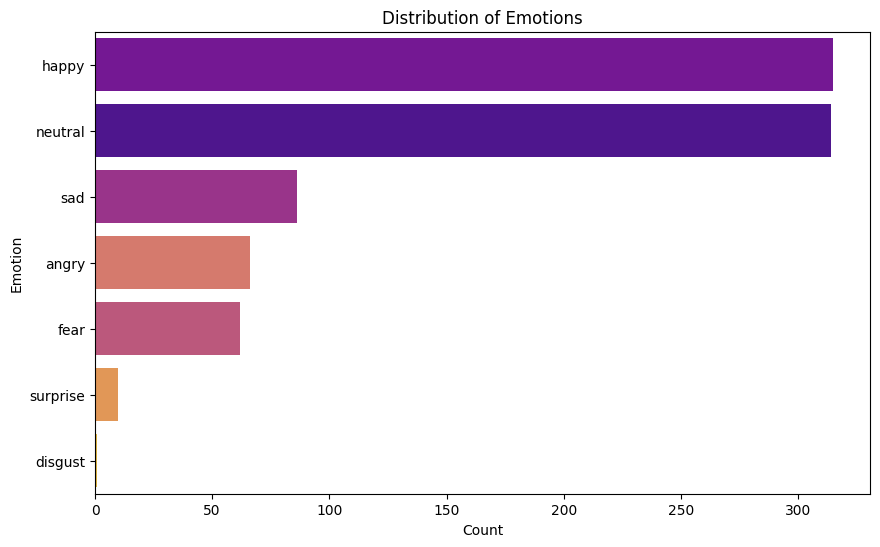

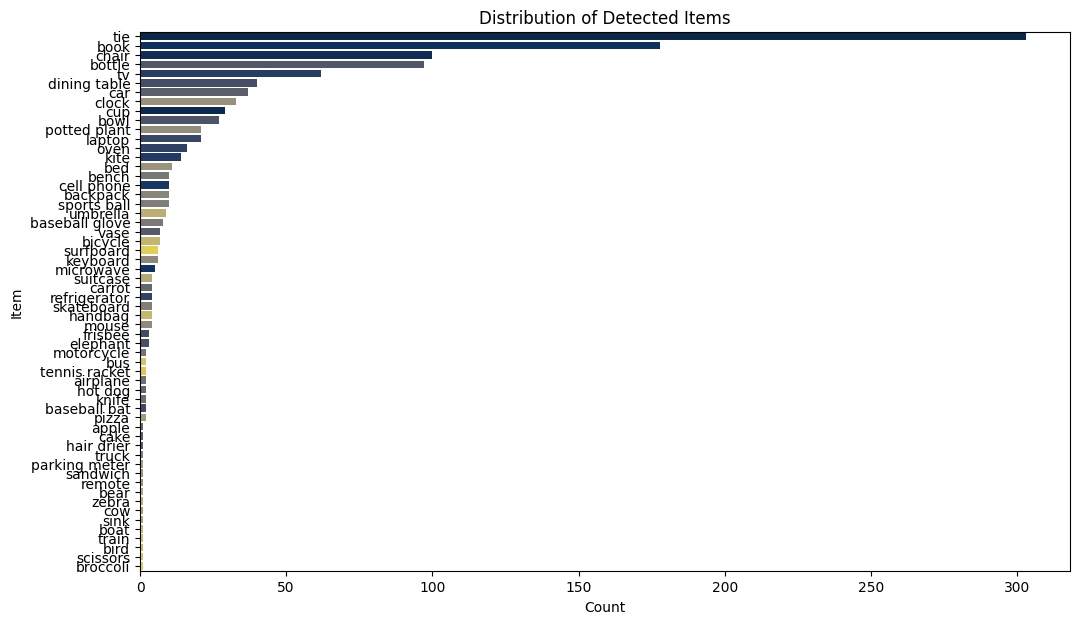

In [ ]:
# Gender Pie Chart
gender_counts = pd.Series(genders).value_counts()
plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Genders')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

# Ages Bar Chart
plt.figure(figsize=(10, 6))
sns.countplot(y=ages, order=sorted(pd.Series(ages).unique()), palette='viridis', hue=ages, legend=False)
plt.title('Distribution of Ages')
plt.xlabel('Count')
plt.ylabel('Age')
plt.show()

# Race Bar Chart
plt.figure(figsize=(10, 6))
sns.countplot(y=races, order=pd.Series(races).value_counts().index, palette='viridis', hue=races, legend=False)
plt.title('Distribution of Races')
plt.xlabel('Count')
plt.ylabel('Race')
plt.show()

# Emotions Bar Chart
plt.figure(figsize=(10, 6))
sns.countplot(y=emotions, order=pd.Series(emotions).value_counts().index, palette='plasma', hue=emotions, legend=False)
plt.title('Distribution of Emotions')
plt.xlabel('Count')
plt.ylabel('Emotion')
plt.show()

# Items Bar Chart
plt.figure(figsize=(12, 7))
sns.countplot(y=item_labels, order=pd.Series(item_labels).value_counts().index, palette='cividis', hue=item_labels, legend=False)
plt.title('Distribution of Detected Items')
plt.xlabel('Count')
plt.ylabel('Item')
plt.show()

### Diversity


      EMBEDDING-BASED DIVERSITY REPORT   
Total Images Analysed: 1030
Average Pairwise Cosine Similarity: 0.5390 (Higher means more redundant)
Average Pairwise Cosine Distance:   0.4610 (Higher means more diverse)
Standard Deviation of Distances:    0.1052


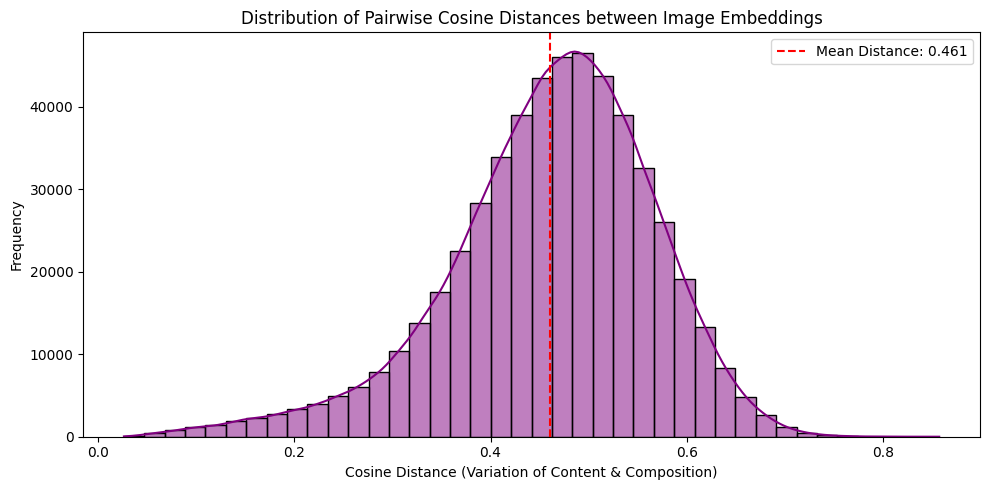

In [ ]:
image_embeddings = []
valid_names = []

# Traverse and load image embeddings from the generated metadata
for data in metadata:
    if 'image_embedding' in data and 'prompt' in data:
        emb = np.array(data['image_embedding']).flatten()
        image_embeddings.append(emb)
        valid_names.append(data['prompt']+str(data['mode']))

if len(image_embeddings) > 1:
    embeddings_matrix = np.array(image_embeddings)

    # Compute pairwise similarity matrix
    similarity_matrix = cosine_similarity(embeddings_matrix)

    # Exclude self-similarity diagonal to get realistic variance/distances
    triu_indices = np.triu_indices_from(similarity_matrix, k=1)
    pairwise_similarities = similarity_matrix[triu_indices]
    pairwise_distances = 1 - pairwise_similarities # Cosine distance

    # Calculate diversity metrics
    mean_similarity = np.mean(pairwise_similarities)
    std_similarity = np.std(pairwise_similarities)
    mean_distance = np.mean(pairwise_distances)
    std_distance = np.std(pairwise_distances)

    print("=========================================")
    print("      EMBEDDING-BASED DIVERSITY REPORT   ")
    print("=========================================")
    print(f"Total Images Analysed: {len(image_embeddings)}")
    print(f"Average Pairwise Cosine Similarity: {mean_similarity:.4f} (Higher means more redundant)")
    print(f"Average Pairwise Cosine Distance:   {mean_distance:.4f} (Higher means more diverse)")
    print(f"Standard Deviation of Distances:    {std_distance:.4f}")
    print("=========================================")

    # Visualize the distribution of pairwise distances (variation/diversity)
    plt.figure(figsize=(10, 5))
    sns.histplot(pairwise_distances, kde=True, color='purple', bins=40)
    plt.axvline(mean_distance, color='red', linestyle='--', label=f'Mean Distance: {mean_distance:.3f}')
    plt.title('Distribution of Pairwise Cosine Distances between Image Embeddings')
    plt.xlabel('Cosine Distance (Variation of Content & Composition)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No image embeddings found in meta.json files or insufficient images to compute pairwise similarity.")

     IMAGE GENERATION DIVERSITY REPORT   
Total Images Evaluated: 1030
Valid Images (face detected): 854 (82.9%)

--- Demographic Diversity (Normalized Entropy [0-1]) ---
- Gender Diversity Entropy:  0.7430 (Unique: 2)
- Racial Diversity Entropy:  0.8364 (Unique: 6)
- Emotion Diversity Entropy: 0.7273 (Unique: 7)
- Item Diversity Entropy:    0.6810 (Unique: 58)

--- Age Variation ---
- Age Standard Deviation:    7.80 years
- Age Range:                 47 years (Min: 20, Max: 67)


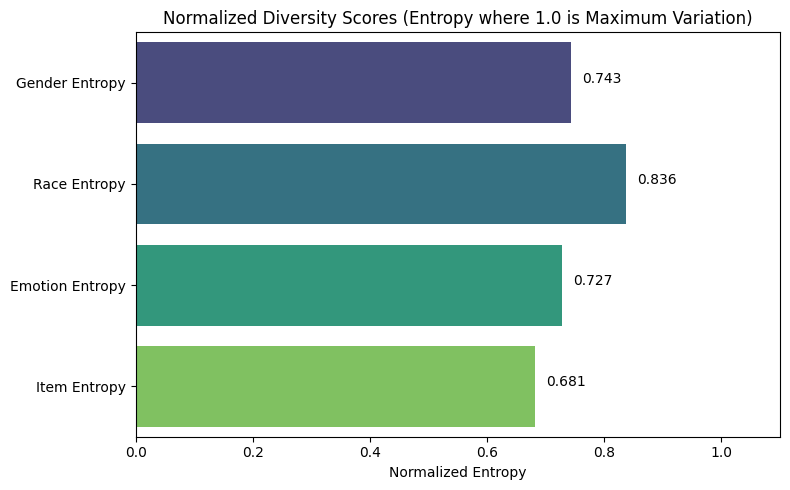

In [ ]:
# Lists to collect features across all valid images
genders = []
races = []
ages = []
emotions = []
all_items = []

# Read YOLO labels
with open(os.path.join(dir, 'yolo_labels.json'), 'r') as f:
    yolo_labels = json.load(f)

total_images = len(metadata)
valid_images = 0

for data in metadata:
    # Check if facial features are valid
    if 'facial_feats' in data and len(data['facial_feats']) > 0:
        if data['facial_feats'][0].get('face_confidence', -1) != -1:
            valid_images += 1
            feat = data['facial_feats'][0]
            genders.append(feat.get('dominant_gender'))
            races.append(feat.get('dominant_race'))
            ages.append(feat.get('age'))
            emotions.append(feat.get('dominant_emotion'))

    # Items present
    if 'items' in data:
        classes = data['items'].get('cls', [])
        labels = [yolo_labels.get(str(int(c)), f'unknown_{c}') for c in classes]
        labels = [l for l in labels if l != 'person']
        all_items.extend(labels)

# Helper function to compute normalized Shannon entropy (higher value means higher diversity / variation)
def compute_normalized_entropy(data_list):
    if not data_list:
        return 0.0
    counts = pd.Series(data_list).value_counts()
    probs = counts / counts.sum()
    n_categories = len(counts)
    if n_categories <= 1:
        return 0.0
    return entropy(probs) / np.log(n_categories)

# Calculate diversity metrics
gender_entropy = compute_normalized_entropy(genders)
race_entropy = compute_normalized_entropy(races)
emotion_entropy = compute_normalized_entropy(emotions)
item_entropy = compute_normalized_entropy(all_items)

age_std = np.std(ages) if ages else 0
age_range = np.ptp(ages) if ages else 0

print("=========================================")
print("     IMAGE GENERATION DIVERSITY REPORT   ")
print("=========================================")
print(f"Total Images Evaluated: {total_images}")
print(f"Valid Images (face detected): {valid_images} ({valid_images/total_images*100:.1f}%)")
print("\n--- Demographic Diversity (Normalized Entropy [0-1]) ---")
print(f"- Gender Diversity Entropy:  {gender_entropy:.4f} (Unique: {len(set(genders))})")
print(f"- Racial Diversity Entropy:  {race_entropy:.4f} (Unique: {len(set(races))})")
print(f"- Emotion Diversity Entropy: {emotion_entropy:.4f} (Unique: {len(set(emotions))})")
print(f"- Item Diversity Entropy:    {item_entropy:.4f} (Unique: {len(set(all_items))})")
print("\n--- Age Variation ---")
print(f"- Age Standard Deviation:    {age_std:.2f} years")
print(f"- Age Range:                 {age_range} years (Min: {min(ages)}, Max: {max(ages)})")
print("=========================================")

# Visualize Diversity Scores
metrics = ['Gender Entropy', 'Race Entropy', 'Emotion Entropy', 'Item Entropy']
symbols = ['G', 'R', 'E', 'I'] # Add symbols for hue
scores = [gender_entropy, race_entropy, emotion_entropy, item_entropy]

plt.figure(figsize=(8, 5))
sns.barplot(x=scores, y=metrics, palette='viridis', hue=metrics, legend=False)
plt.xlim(0, 1.1)
plt.title('Normalized Diversity Scores (Entropy where 1.0 is Maximum Variation)')
plt.xlabel('Normalized Entropy')
for index, value in enumerate(scores):
    plt.text(value + 0.02, index, f'{value:.3f}')
plt.tight_layout()
plt.show()

In [ ]:
# Lists to collect features across all valid images
genders_all = []
races_all = []
ages_all = []
emotions_all = []
items_all = []

# Read YOLO labels
with open(os.path.join(dir, 'yolo_labels.json'), 'r') as f:
    yolo_labels = json.load(f)

total_images = len(metadata)
valid_images = 0

for data in metadata:
    # Check if facial features are valid
    if 'facial_feats' in data and len(data['facial_feats']) > 0:
        if data['facial_feats'][0].get('face_confidence', -1) != -1:
            valid_images += 1
            feat = data['facial_feats'][0]
            genders_all.append(feat.get('dominant_gender'))
            races_all.append(feat.get('dominant_race'))
            ages_all.append(feat.get('age'))
            emotions_all.append(feat.get('dominant_emotion'))

    # Items present
    if 'items' in data:
        classes = data['items'].get('cls', [])
        labels = [yolo_labels.get(str(int(c)), f'unknown_{c}') for c in classes]
        labels = [l for l in labels if l != 'person']
        items_all.extend(labels)

# Helper function to compute normalized Shannon entropy
def compute_normalized_entropy(data_list):
    if not data_list:
        return 0.0
    counts = pd.Series(data_list).value_counts()
    probs = counts / counts.sum()
    n_categories = len(counts)
    if n_categories <= 1:
        return 0.0
    return entropy(probs) / np.log(n_categories)

# Helper function to format value distributions
def print_value_distribution(name, data_list):
    if not data_list:
        print(f"No data for {name}")
        return
    counts = pd.Series(data_list).value_counts()
    total = sum(counts)
    print(f"\n--- {name} Breakdown ---")
    for val, count in counts.items():
        pct = (count / total) * 100
        print(f"- {val}: {count} ({pct:.1f}%)")

# Calculate diversity metrics
gender_entropy = compute_normalized_entropy(genders_all)
race_entropy = compute_normalized_entropy(races_all)
emotion_entropy = compute_normalized_entropy(emotions_all)
item_entropy = compute_normalized_entropy(items_all)

age_std = np.std(ages_all) if ages_all else 0
age_range = np.ptp(ages_all) if ages_all else 0

print("=========================================")
print("     ENHANCED DIVERSITY REPORT           ")
print("=========================================")
print(f"Total Images Evaluated: {total_images}")
print(f"Valid Images (face detected): {valid_images} ({valid_images/total_images*100:.1f}%)")

print("\n=========================================")
print("      DEMOGRAPHIC VALUE DIVERSITY        ")
print("=========================================")
print_value_distribution("Gender (Dominant)", genders_all)
print_value_distribution("Race (Dominant)", races_all)
print_value_distribution("Emotion (Dominant)", emotions_all)

print("\n--- Top 10 Detected Items ---")
item_counts = pd.Series(items_all).value_counts().head(10)
for item, count in item_counts.items():
    print(f"- {item}: {count}")

print("\n=========================================")
print("    SUMMARY ENTROPY & VARIATION METRICS  ")
print("=========================================")
print(f"- Gender Diversity Entropy:  {gender_entropy:.4f} (Unique: {len(set(genders_all))})")
print(f"- Racial Diversity Entropy:  {race_entropy:.4f} (Unique: {len(set(races_all))})")
print(f"- Emotion Diversity Entropy: {emotion_entropy:.4f} (Unique: {len(set(emotions_all))})")
print(f"- Item Diversity Entropy:    {item_entropy:.4f} (Unique: {len(set(items_all))})")
print(f"- Age Standard Deviation:    {age_std:.2f} years")
print(f"- Age Range:                 {age_range} years (Min: {min(ages_all)}, Max: {max(ages_all)})")
print("=========================================")

     ENHANCED DIVERSITY REPORT           
Total Images Evaluated: 1030
Valid Images (face detected): 854 (82.9%)

      DEMOGRAPHIC VALUE DIVERSITY        

--- Gender (Dominant) Breakdown ---
- Man: 674 (78.9%)
- Woman: 180 (21.1%)

--- Race (Dominant) Breakdown ---
- white: 364 (42.6%)
- black: 153 (17.9%)
- asian: 144 (16.9%)
- middle eastern: 121 (14.2%)
- latino hispanic: 58 (6.8%)
- indian: 14 (1.6%)

--- Emotion (Dominant) Breakdown ---
- happy: 315 (36.9%)
- neutral: 314 (36.8%)
- sad: 86 (10.1%)
- angry: 66 (7.7%)
- fear: 62 (7.3%)
- surprise: 10 (1.2%)
- disgust: 1 (0.1%)

--- Top 10 Detected Items ---
- tie: 306
- book: 178
- chair: 101
- bottle: 97
- tv: 62
- dining table: 40
- car: 37
- clock: 34
- cup: 29
- bowl: 27

    SUMMARY ENTROPY & VARIATION METRICS  
- Gender Diversity Entropy:  0.7430 (Unique: 2)
- Racial Diversity Entropy:  0.8364 (Unique: 6)
- Emotion Diversity Entropy: 0.7273 (Unique: 7)
- Item Diversity Entropy:    0.6810 (Unique: 58)
- Age Standard Deviation

     INTERNAL CONTENT DIVERSITY PER DEMOGRAPHIC VALUE             
   (Higher Average Pairwise Cosine Distance = More Diverse Subgroup) 

--- Gender Value Diversity Breakdown ---
- Man              : Diversity = 0.4646 (Samples: 674)
- Woman            : Diversity = 0.3693 (Samples: 180)

--- Race Value Diversity Breakdown ---
- Indian           : Diversity = 0.4817 (Samples: 14)
- White            : Diversity = 0.4433 (Samples: 364)
- Latino hispanic  : Diversity = 0.4364 (Samples: 58)
- Black            : Diversity = 0.4283 (Samples: 153)
- Asian            : Diversity = 0.4266 (Samples: 144)
- Middle eastern   : Diversity = 0.4184 (Samples: 121)

--- Emotion Value Diversity Breakdown ---
- Sad              : Diversity = 0.4775 (Samples: 86)
- Neutral          : Diversity = 0.4710 (Samples: 314)
- Fear             : Diversity = 0.4685 (Samples: 62)
- Angry            : Diversity = 0.4507 (Samples: 66)
- Happy            : Diversity = 0.4029 (Samples: 315)
- Surprise         : Diversi

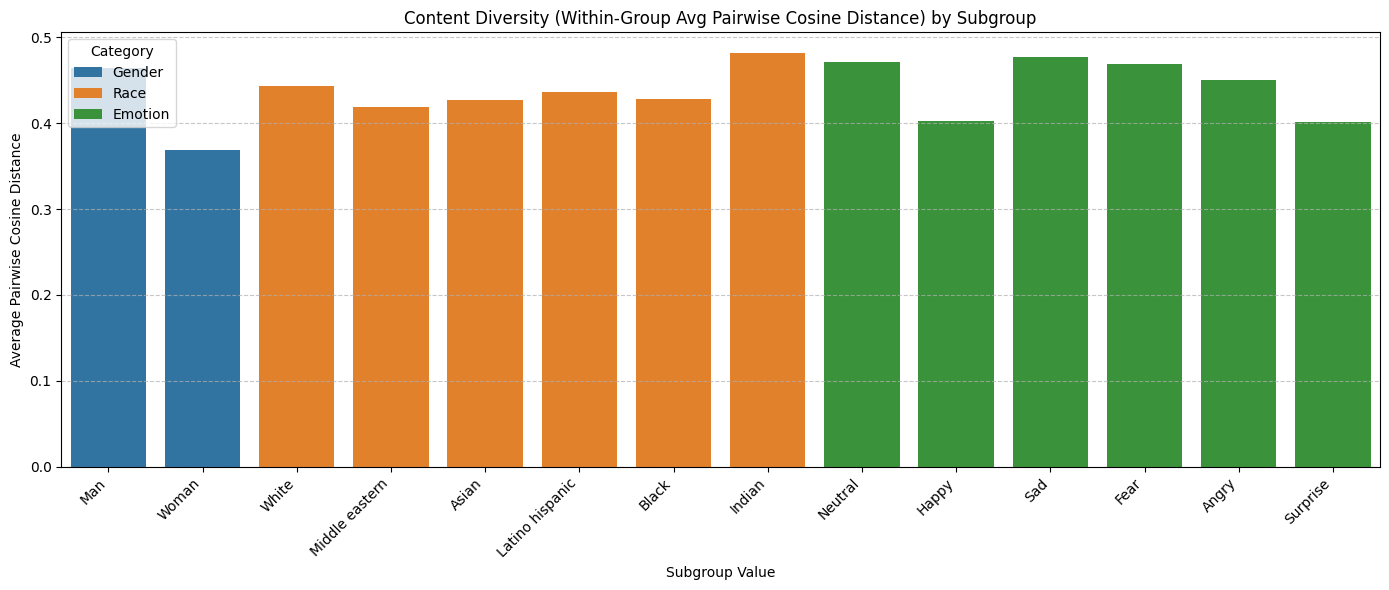

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

# 1. Match each valid image's embedding with its corresponding detected attributes
valid_embeddings = []
matched_genders = []
matched_races = []
matched_emotions = []

for data in metadata:
    if 'image_embedding' in data and 'facial_feats' in data and len(data['facial_feats']) > 0:
        if data['facial_feats'][0].get('face_confidence', -1) != -1:
            emb = np.array(data['image_embedding']).flatten()
            feat = data['facial_feats'][0]

            valid_embeddings.append(emb)
            matched_genders.append(feat.get('dominant_gender'))
            matched_races.append(feat.get('dominant_race'))
            matched_emotions.append(feat.get('dominant_emotion'))

X_embeddings = np.array(valid_embeddings)

# Helper function to compute internal diversity (average pairwise cosine distance)
def calculate_group_diversity(embeddings_subset):
    n_samples = len(embeddings_subset)
    if n_samples <= 1:
        return 0.0
    # Pairwise similarity matrix
    sim_matrix = cosine_similarity(embeddings_subset)
    # Get upper triangle indices (excluding self-similarity diagonal)
    triu_idx = np.triu_indices_from(sim_matrix, k=1)
    pairwise_distances = 1 - sim_matrix[triu_idx]
    return np.mean(pairwise_distances)

# 2. Compute within-group diversity for each category value
categories = {
    'Gender': matched_genders,
    'Race': matched_races,
    'Emotion': matched_emotions
}

diversity_records = []

for cat_name, val_list in categories.items():
    series = pd.Series(val_list)
    unique_vals = series.dropna().unique()

    for val in unique_vals:
        # Get indices of images belonging to this value
        indices = series[series == val].index
        # Subset embeddings
        group_embs = X_embeddings[indices]

        # Compute average pairwise cosine distance as the diversity index
        group_div = calculate_group_diversity(group_embs)

        diversity_records.append({
            'Category': cat_name,
            'Value': val.capitalize() if isinstance(val, str) else val,
            'Diversity (Avg Pairwise Distance)': group_div,
            'Sample Count': len(indices)
        })

df_group_diversity = pd.DataFrame(diversity_records)

# 3. Print the report
print("=================================================================")
print("     INTERNAL CONTENT DIVERSITY PER DEMOGRAPHIC VALUE             ")
print("   (Higher Average Pairwise Cosine Distance = More Diverse Subgroup) ")
print("=================================================================")
for cat_name in categories.keys():
    print(f"\n--- {cat_name} Value Diversity Breakdown ---")
    df_subset = df_group_diversity[df_group_diversity['Category'] == cat_name].sort_values(by='Diversity (Avg Pairwise Distance)', ascending=False)
    for _, row in df_subset.iterrows():
        print(f"- {row['Value']:16s} : Diversity = {row['Diversity (Avg Pairwise Distance)']:.4f} (Samples: {row['Sample Count']})")

# 4. Plot the comparison
plt.figure(figsize=(14, 6))
sns.barplot(
    data=df_group_diversity[df_group_diversity['Sample Count'] >= 3],
    x='Value',
    y='Diversity (Avg Pairwise Distance)',
    hue='Category',
    dodge=False
)
plt.title('Content Diversity (Within-Group Avg Pairwise Cosine Distance) by Subgroup')
plt.ylabel('Average Pairwise Cosine Distance')
plt.xlabel('Subgroup Value')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Prompt adherence

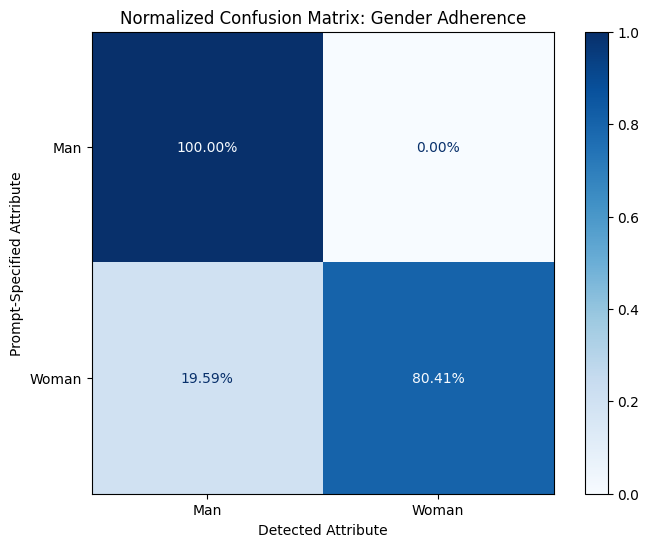

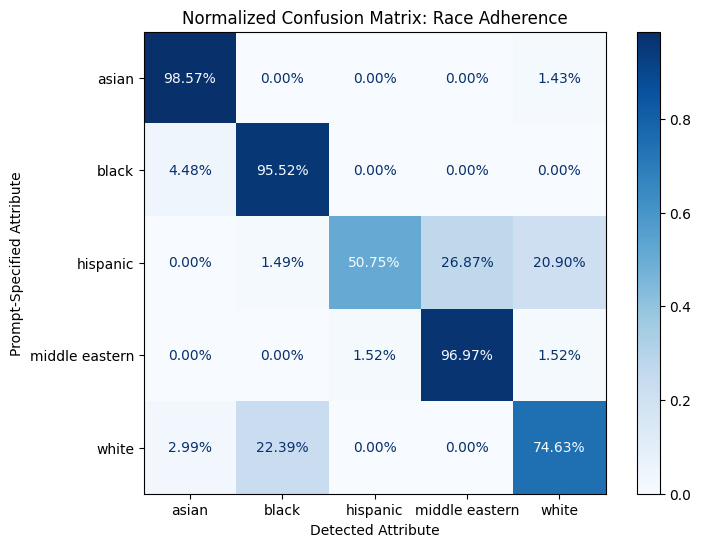

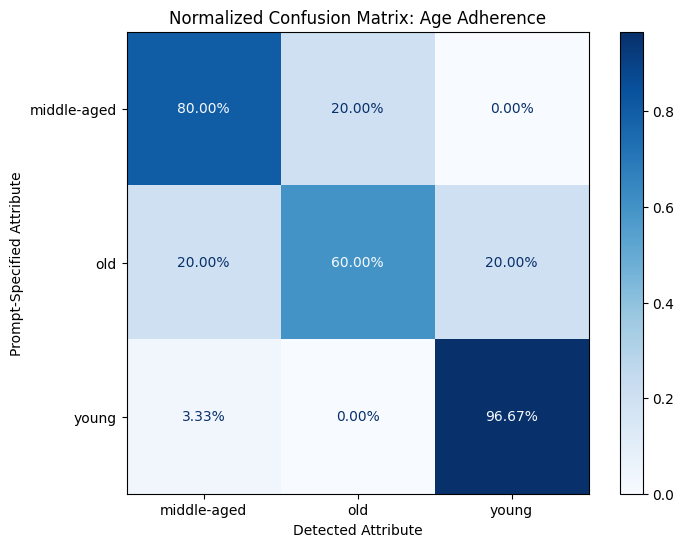

In [ ]:
ages = ['young', 'old', 'middle-aged']
genders = ['male', 'female']
genders_noun = ['man', 'woman']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']
gender_true = []
gender_pred = []
race_true = []
race_pred = []
age_true = []
age_pred = []

for data in metadata:
    prompt = data.get('prompt', '').lower()

    # Check facial features
    if 'facial_feats' in data and len(data['facial_feats']) > 0:
      if data['facial_feats'][0].get('face_confidence', -1) != -1:
          feat = data['facial_feats'][0]

          # Collect gender mapping
          specified_gender = None
          if 'female' in prompt or 'woman' in prompt:
              specified_gender = 'Woman'
          elif 'male' in prompt or 'man' in prompt:
              specified_gender = 'Man'

          if specified_gender:
              detected_gender = feat.get('dominant_gender')
              # Standardize to title-case 'Man' or 'Woman'
              if detected_gender:
                  detected_gender = detected_gender.strip().capitalize()
                  if detected_gender in ['Man', 'Woman']:
                      gender_true.append(specified_gender)
                      gender_pred.append(detected_gender)

          # Collect race mapping
          specified_race = None
          for r in races:
              if r in prompt:
                  specified_race = r
                  break

          if specified_race:
              detected_race_raw = feat.get('dominant_race', '').lower()
              detected_race = 'unknown'
              if 'latino' in detected_race_raw or 'hispanic' in detected_race_raw:
                  detected_race = 'hispanic'
              else:
                  for r in races:
                      if r in detected_race_raw:
                          detected_race = r
                          break

              race_true.append(specified_race)
              race_pred.append(detected_race)

          # Collect age mapping
          specified_age = None
          for a in ages:
              if a in prompt:
                  specified_age = a
                  break

          if specified_age:
              detected_age_val = feat.get('age')
              if detected_age_val is not None:
                  if detected_age_val < 30:
                      detected_age_cat = 'young'
                  elif detected_age_val > 50:
                      detected_age_cat = 'old'
                  else:
                      detected_age_cat = 'middle-aged'

                  age_true.append(specified_age)
                  age_pred.append(detected_age_cat)

# Helper function to plot normalized confusion matrix
def plot_normalized_cm(true_vals, pred_vals, labels, title):
    if len(true_vals) == 0:
        print(f"No data to plot for {title}")
        return

    unique_labels = sorted(list(set(labels)))
    cm = confusion_matrix(true_vals, pred_vals, labels=unique_labels)

    # Normalize by row (true labels)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)

    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=unique_labels)
    disp.plot(cmap='Blues', ax=ax, values_format='.2%')
    plt.title(f'Normalized Confusion Matrix: {title}')
    plt.xlabel('Detected Attribute')
    plt.ylabel('Prompt-Specified Attribute')
    plt.show()

# Plot the Confusion Matrices
plot_normalized_cm(gender_true, gender_pred, ['Man', 'Woman'], 'Gender Adherence')
plot_normalized_cm(race_true, race_pred, races, 'Race Adherence')
plot_normalized_cm(age_true, age_pred, ages, 'Age Adherence')

### Clustering / separability

Loaded 854 valid face embeddings for demographic clustering.
                DEMOGRAPHIC CLUSTERING PERFORMANCE                      
Gender Clustering    | Silhouette Score: 0.0217 | ARI: 0.1060
Race Clustering      | Silhouette Score: 0.0127 | ARI: 0.0254
Age Group Clustering | Silhouette Score: -0.0078 | ARI: -0.0347
Job Clustering       | Silhouette Score: -0.0618 | ARI: 0.0559


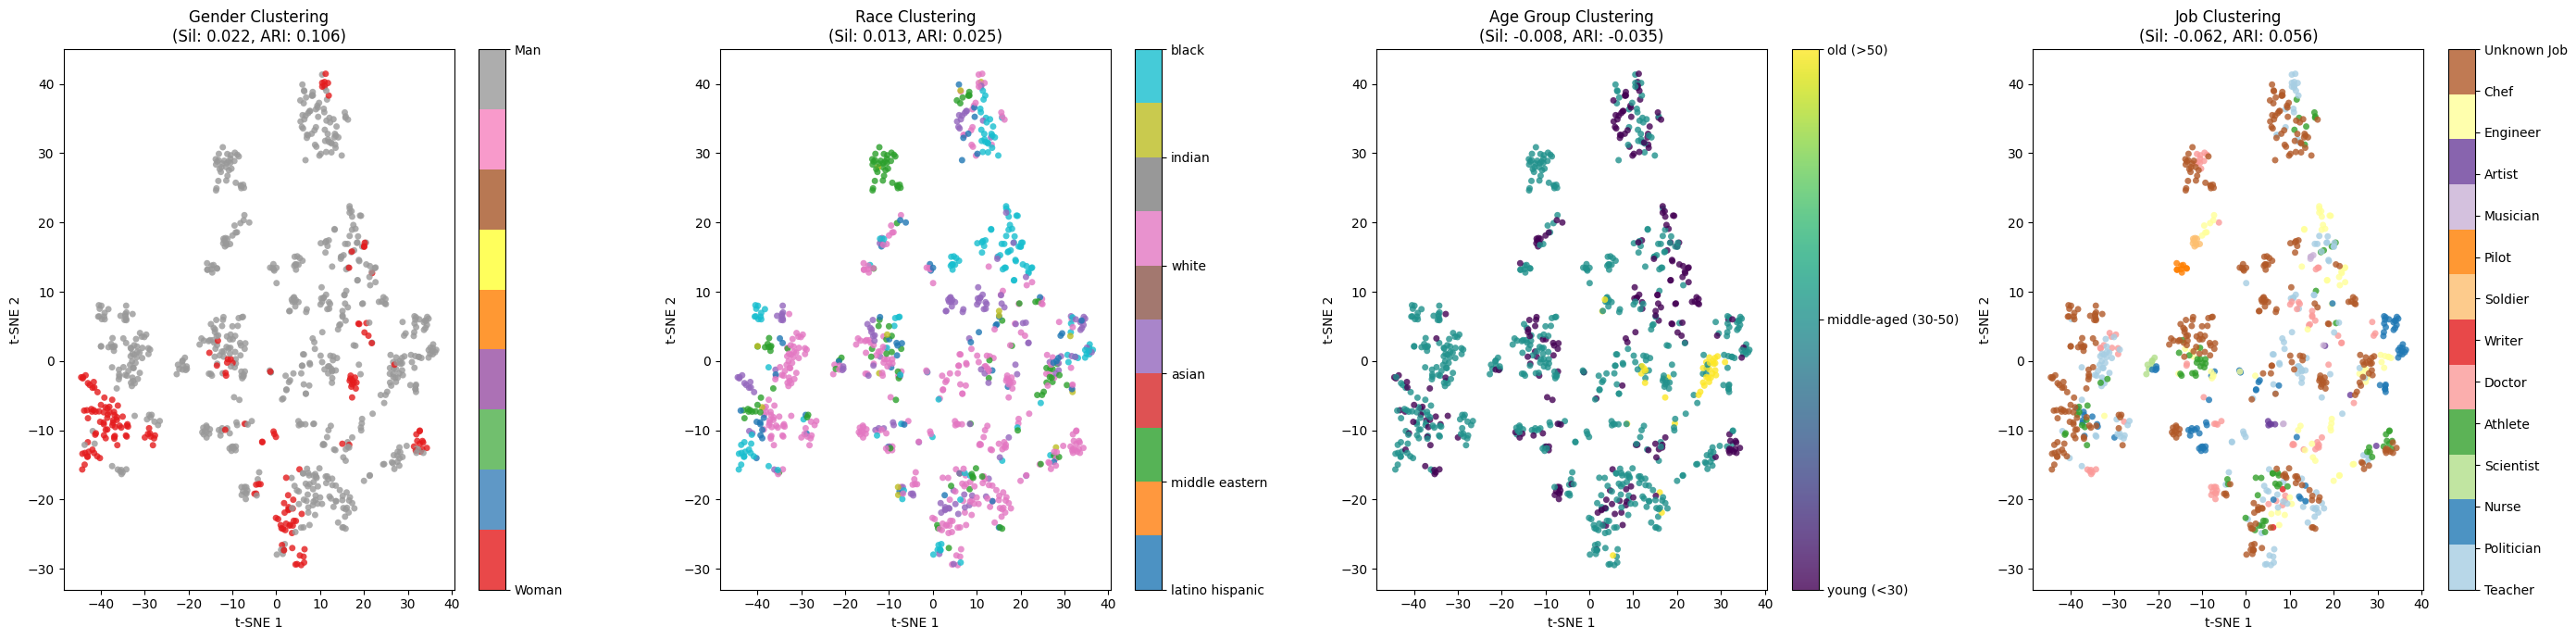

In [ ]:
# Arrays to collect valid data
embs_valid = []
genders_list = []
races_list = []
age_groups_list = []
jobs_list = []

# Define jobs for extraction
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']

for data in metadata:
    if 'image_embedding' in data and 'facial_feats' in data and len(data['facial_feats']) > 0:
        feat = data['facial_feats'][0]
        if feat.get('face_confidence', -1) != -1:
            gender = feat.get('dominant_gender')
            race = feat.get('dominant_race')
            age = feat.get('age')
            prompt = data.get('prompt', '').lower()

            # Extract job from prompt
            matched_job = next((job for job in jobs if job in prompt), None)

            if gender and race and age is not None:
                emb = np.array(data['image_embedding']).flatten()
                embs_valid.append(emb)
                genders_list.append(gender)
                races_list.append(race)

                # Categorize age into groups
                if age < 30:
                    age_groups_list.append('young (<30)')
                elif age > 50:
                    age_groups_list.append('old (>50)')
                else:
                    age_groups_list.append('middle-aged (30-50)')

                # Add job if found, else a placeholder
                jobs_list.append(matched_job.capitalize() if matched_job else 'Unknown Job')

X_dem = np.array(embs_valid)
print(f"Loaded {len(X_dem)} valid face embeddings for demographic clustering.")

# Common t-SNE Projection for consistent visual comparison
tsne_dem = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d_dem = tsne_dem.fit_transform(X_dem)

# Helper to evaluate clustering and plot
def evaluate_and_plot(X_raw, X_2d, labels, title, subplot_pos, cmap):
    unique_lbls = list(set(labels))
    # Filter out 'Unknown Job' if present and not the only label
    if 'Unknown Job' in unique_lbls and len(unique_lbls) > 1:
        unique_lbls.remove('Unknown Job')
        # Move 'Unknown Job' to the end for consistent color mapping if it exists
        labels_filtered = [lbl for lbl in labels if lbl != 'Unknown Job']
        labels_unknown = [lbl for lbl in labels if lbl == 'Unknown Job']
        labels_plot = labels_filtered + labels_unknown
        unique_lbls_plot = unique_lbls + ['Unknown Job']
    else:
        labels_plot = labels
        unique_lbls_plot = unique_lbls

    if not unique_lbls_plot:
        print(f"No valid labels for {title}, skipping plot.")
        return

    lbl_to_idx = {l: i for i, l in enumerate(unique_lbls_plot)}
    y_true_idx = np.array([lbl_to_idx[l] for l in labels_plot])

    n_cl = len(unique_lbls_plot)
    # Only perform K-Means if there's more than one cluster target and enough samples
    if n_cl > 1 and len(X_raw) >= n_cl:
        km = KMeans(n_clusters=n_cl, random_state=42, n_init=10)
        y_pred_idx = km.fit_predict(X_raw)
        sil = silhouette_score(X_raw, y_true_idx)
        ari = adjusted_rand_score(y_true_idx, y_pred_idx)
    else:
        sil = np.nan # Not applicable
        ari = np.nan # Not applicable

    print(f"{title:20s} | Silhouette Score: {sil:.4f} | ARI: {ari:.4f}")

    ax = plt.subplot(1, 4, subplot_pos)
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_true_idx, cmap=cmap, alpha=0.8, edgecolors='none', s=25)

    # Setup colorbar ticks and labels
    cbar = plt.colorbar(sc, ax=ax, ticks=range(n_cl))
    cbar.ax.set_yticklabels(unique_lbls_plot)
    ax.set_title(f"{title}\n(Sil: {sil:.3f}, ARI: {ari:.3f})")
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

# Setup side-by-side plots
print("=========================================================================")
print("                DEMOGRAPHIC CLUSTERING PERFORMANCE                      ")
print("=========================================================================")
plt.figure(figsize=(28, 7)) # Adjusted figure size for 4 plots
evaluate_and_plot(X_dem, X_2d_dem, genders_list, 'Gender Clustering', 1, 'Set1')
evaluate_and_plot(X_dem, X_2d_dem, races_list, 'Race Clustering', 2, 'tab10')
evaluate_and_plot(X_dem, X_2d_dem, age_groups_list, 'Age Group Clustering', 3, 'viridis')
evaluate_and_plot(X_dem, X_2d_dem, jobs_list, 'Job Clustering', 4, 'Paired') # New plot for jobs
plt.tight_layout()
plt.show()

### Visualizations

In [ ]:
import random
import os
import json
from PIL import Image
import matplotlib.pyplot as plt

# Select 10 random metadata entries
sampled_metadata = random.sample(metadata, min(10, len(metadata)))

for data in sampled_metadata:
    # Construct the image path using information from the metadata
    image_id = data['name'].replace('.png', '')
    mode_dir = f"gen_images_m{data['mode']}"
    # Assuming 'dir' is defined in a previous cell and points to the base directory
    image_dir = os.path.join(dir, mode_dir, image_id)
    image_file_path = os.path.join(image_dir, data['name'])

    if os.path.exists(image_file_path):
        prompt_text = data.get('prompt', 'No prompt available')
        face_confidence = data['facial_feats'][0].get('face_confidence', -1) if 'facial_feats' in data and len(data['facial_feats']) > 0 else 'N/A'

        print(f"{prompt_text} - valid {face_confidence}")
        img = Image.open(image_file_path)
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    else:
        print(f"Image not found: {image_file_path}")


Output hidden; open in https://colab.research.google.com to view.

# Biases

In [ ]:
# Filter metadata for mode == 1 and valid faces
mode1_association_matrices = []

# Define search lists
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']
workplaces = ['office', 'factory', 'hospital', 'school', 'restaurant', 'store', 'laboratory', 'construction site']
genders_list = ['male', 'female', 'man', 'woman']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']
ages = ['young', 'old', 'middle-aged']
statuses = ['successful', 'homeless', 'wealthy', 'poor']
emotions_list = ['happy', 'sad', 'angry', 'calm', 'bored', 'nervous']
toxics = ['criminal', 'gang member', 'uneducated person', 'terrorist', 'manipulative person']
positives = ['intelligent', 'trustworthy', 'professional', 'hardworking']
continents = ['Europe', 'Asia', 'Africa', 'North America', 'South America']

for data in metadata:
    if data.get('mode') == 1:
        # Check facial features
        if 'facial_feats' in data and len(data['facial_feats']) > 0:
            feat = data['facial_feats'][0]
            if feat.get('face_confidence', -1) != -1:
                prompt = data.get('prompt', '').lower()

                # Extract prompt variables
                matched_job = next((j for j in jobs if j in prompt), None)
                matched_workplace = next((w for workplaces_item in workplaces for w in [workplaces_item] if w in prompt), None)
                matched_gender_prompt = next((g for g in genders_list if g in prompt), None)
                matched_race_prompt = next((r for r in races if r in prompt), None)
                matched_age_prompt = next((a for a in ages if a in prompt), None)
                matched_status = next((s for s in statuses if s in prompt), None)
                matched_emotion_prompt = next((e for e in emotions_list if e in prompt), None)
                matched_toxic = next((t for t in toxics if t in prompt), None)
                matched_positive = next((p for p in positives if p in prompt), None)
                matched_continent = next((c for c in continents if c.lower() in prompt), None)

                # Extract outputs
                detected_gender = feat.get('dominant_gender') # 'Man' or 'Woman'
                detected_race = feat.get('dominant_race')
                detected_age = feat.get('age')
                detected_emotion = feat.get('dominant_emotion')

                mode1_association_matrices.append({
                    'job': matched_job.capitalize() if matched_job else None,
                    'workplace': matched_workplace.capitalize() if matched_workplace else None,
                    'gender_prompt': matched_gender_prompt.capitalize() if matched_gender_prompt else None,
                    'race_prompt': matched_race_prompt.capitalize() if matched_race_prompt else None,
                    'age_prompt': matched_age_prompt.capitalize() if matched_age_prompt else None,
                    'status': matched_status.capitalize() if matched_status else None,
                    'emotion_prompt': matched_emotion_prompt.capitalize() if matched_emotion_prompt else None,
                    'toxic': matched_toxic.capitalize() if matched_toxic else None,
                    'positive': matched_positive.capitalize() if matched_positive else None,
                    'continent': matched_continent.capitalize() if matched_continent else None,
                    'detected_gender': detected_gender,
                    'detected_race': detected_race.capitalize() if detected_race else None,
                    'detected_emotion': detected_emotion.capitalize() if detected_emotion else None,
                    'detected_age': detected_age if detected_age else None,
                })

df_m1 = pd.DataFrame(mode1_association_matrices)

def build_association_matrix(df, index_col, target_col):
    filtered = df.dropna(subset=[index_col, target_col])
    if filtered.empty:
        return f"No data available for association of {target_col} given {index_col}."
    pivot = filtered.groupby([index_col, target_col]).size().unstack(fill_value=0)
    pct_matrix = pivot.div(pivot.sum(axis=1), axis=0) * 100
    pct_matrix = pct_matrix.round(1).astype(str) + '%'
    pct_matrix['Total Count'] = pivot.sum(axis=1)
    return pct_matrix

# Create and display association matrices
matrices = {
    "Gender given Job": build_association_matrix(df_m1, 'job', 'detected_gender'),
    "Gender given Workplace": build_association_matrix(df_m1, 'workplace', 'detected_gender'),
    "Gender given Race (Prompt)": build_association_matrix(df_m1, 'race_prompt', 'detected_gender'),
    "Gender given Age (Prompt)": build_association_matrix(df_m1, 'age_prompt', 'detected_gender'),
    "Gender given Emotion (Prompt)": build_association_matrix(df_m1, 'emotion_prompt', 'detected_gender'),
    "Gender given Status": build_association_matrix(df_m1, 'status', 'detected_gender'),
    "Gender given Toxic Trait": build_association_matrix(df_m1, 'toxic', 'detected_gender'),
    "Gender given Positive Trait": build_association_matrix(df_m1, 'positive', 'detected_gender'),
    "Gender given Continent": build_association_matrix(df_m1, 'continent', 'detected_gender'),

    "Race given Job": build_association_matrix(df_m1, 'job', 'detected_race'),
    "Race given Workplace": build_association_matrix(df_m1, 'workplace', 'detected_race'),
    "Race given Gender": build_association_matrix(df_m1, 'gender_prompt', 'detected_race'),
    "Race given Age (Prompt)": build_association_matrix(df_m1, 'age_prompt', 'detected_race'),
    "Race given Emotions (Prompt)": build_association_matrix(df_m1, 'emotion_prompt', 'detected_race'),
    "Race given Status": build_association_matrix(df_m1, 'status', 'detected_race'),
    "Race given Toxic Trait": build_association_matrix(df_m1, 'toxic', 'detected_race'),
    "Race given Positive Trait": build_association_matrix(df_m1, 'positive', 'detected_race'),
    "Race given Continent": build_association_matrix(df_m1, 'continent', 'detected_race'),

    "Age given Job": build_association_matrix(df_m1, 'job', 'detected_age'),
    "Age given Workplace": build_association_matrix(df_m1, 'workplace', 'detected_age'),
    "Age given Gender": build_association_matrix(df_m1, 'gender_prompt', 'detected_age'),
    "Age given Race (Prompt)": build_association_matrix(df_m1, 'race_prompt', 'detected_age'),
    "Age given Emotions (Prompt)": build_association_matrix(df_m1, 'emotion_prompt', 'detected_age'),
    "Age given Status": build_association_matrix(df_m1, 'status', 'detected_age'),
    "Age given Toxic Trait": build_association_matrix(df_m1, 'toxic', 'detected_age'),
    "Age given Positive Trait": build_association_matrix(df_m1, 'positive', 'detected_age'),
    "Age given Continent": build_association_matrix(df_m1, 'continent', 'detected_age'),

    "Emotion given Job": build_association_matrix(df_m1, 'job', 'detected_emotion'),
    "Emotion given Workplace": build_association_matrix(df_m1, 'workplace', 'detected_emotion'),
    "Emotion given Gender": build_association_matrix(df_m1, 'gender_prompt', 'detected_emotion'),
    "Emotion given Race (Prompt)": build_association_matrix(df_m1, 'race_prompt', 'detected_emotion'),
    "Emotion given Age (Prompt)": build_association_matrix(df_m1, 'age_prompt', 'detected_emotion'),
    "Emotion given Status": build_association_matrix(df_m1, 'status', 'detected_emotion'),
    "Emotion given Toxic Trait": build_association_matrix(df_m1, 'toxic', 'detected_emotion'),
    "Emotion given Positive Trait": build_association_matrix(df_m1, 'positive', 'detected_emotion'),
    "Emotion given Continent": build_association_matrix(df_m1, 'continent', 'detected_emotion'),
}

for title, matrix in matrices.items():
    print(f"\n{'='*20} {title} {'='*20}")
    if isinstance(matrix, pd.DataFrame):
        display(matrix)
    else:
        print(matrix)


==================== Gender given Job ====================


detected_gender,Man,Woman,Total Count
job,,,
Artist,100.0%,0.0%,8
Athlete,100.0%,0.0%,8
Chef,100.0%,0.0%,10
Doctor,100.0%,0.0%,10
Engineer,100.0%,0.0%,7
Musician,100.0%,0.0%,7
Nurse,0.0%,100.0%,10
Pilot,100.0%,0.0%,9
Politician,100.0%,0.0%,8



==================== Gender given Workplace ====================


detected_gender,Man,Woman,Total Count
workplace,,,
Construction site,100.0%,0.0%,6
Factory,50.0%,50.0%,2
Hospital,100.0%,0.0%,6
Laboratory,100.0%,0.0%,4
Office,100.0%,0.0%,2
Restaurant,85.7%,14.3%,7
School,100.0%,0.0%,10
Store,100.0%,0.0%,7



==================== Gender given Race (Prompt) ====================


...

detected_emotion,Angry,Fear,Happy,Neutral,Sad,Total Count
toxic,,,,,,
Criminal,11.1%,11.1%,0.0%,55.6%,22.2%,9
Gang member,0.0%,0.0%,0.0%,100.0%,0.0%,10
Manipulative person,50.0%,50.0%,0.0%,0.0%,0.0%,2
Terrorist,14.3%,14.3%,28.6%,42.9%,0.0%,7
Uneducated person,22.2%,11.1%,11.1%,11.1%,44.4%,9



==================== Emotion given Positive Trait ====================


detected_emotion,Angry,Happy,Neutral,Sad,Total Count
positive,,,,,
Hardworking,66.7%,0.0%,16.7%,16.7%,6
Intelligent,0.0%,50.0%,50.0%,0.0%,4
Professional,30.0%,30.0%,40.0%,0.0%,10
Trustworthy,0.0%,33.3%,66.7%,0.0%,3



==================== Emotion given Continent ====================


detected_emotion,Angry,Fear,Happy,Neutral,Sad,Total Count
continent,,,,,,
Africa,0.0%,0.0%,30.0%,50.0%,20.0%,10
Asia,11.1%,0.0%,16.7%,55.6%,16.7%,18
Europe,0.0%,0.0%,25.0%,50.0%,25.0%,4
North america,0.0%,0.0%,0.0%,66.7%,33.3%,3
South america,0.0%,12.5%,12.5%,62.5%,12.5%,8


In [ ]:
# Filter metadata for mode == 2 and valid faces
mode2_association_matrices = []

# Define search lists
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']
genders_list = ['male', 'female', 'man', 'woman']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']
ages = ['young', 'old', 'middle-aged']

for data in metadata:
    if data.get('mode') == 2:
        if 'facial_feats' in data and len(data['facial_feats']) > 0:
            feat = data['facial_feats'][0]
            if feat.get('face_confidence', -1) != -1:
                prompt = data.get('prompt', '').lower()

                # Extract variables from prompt
                matched_gender = next((g for g in genders_list if g in prompt), None)
                matched_job = next((j for j in jobs if j in prompt), None)
                matched_race = next((r for r in races if r in prompt), None)
                matched_age = next((a for a in ages if a in prompt), None)

                # Standardize gender prompt label
                if matched_gender in ['female', 'woman']:
                    gender_label = 'Woman'
                elif matched_gender in ['male', 'man']:
                    gender_label = 'Man'
                else:
                    gender_label = None

                # Create representation for prompt pairs
                gender_job_pair = f"{gender_label} x {matched_job.capitalize()}" if (gender_label and matched_job) else None
                race_job_pair = f"{matched_race.capitalize()} x {matched_job.capitalize()}" if (matched_race and matched_job) else None
                age_gender_pair = f"{matched_age.capitalize()} x {gender_label}" if (matched_age and gender_label) else None

                # Extract face attributes outputs
                detected_gender = feat.get('dominant_gender') # 'Man' or 'Woman'
                detected_race = feat.get('dominant_race')
                detected_age = feat.get('age')
                detected_emotion = feat.get('dominant_emotion')

                mode2_association_matrices.append({
                    'gender_job_prompt': gender_job_pair,
                    'race_job_prompt': race_job_pair,
                    'age_gender_prompt': age_gender_pair,
                    'detected_gender': detected_gender,
                    'detected_race': detected_race.capitalize() if detected_race else None,
                    'detected_emotion': detected_emotion.capitalize() if detected_emotion else None,
                    'detected_age': detected_age if detected_age else None,
                })

df_m2 = pd.DataFrame(mode2_association_matrices)

def build_double_var_matrix(df, index_col, target_col):
    filtered = df.dropna(subset=[index_col, target_col])
    if filtered.empty:
        return f"No data available for {target_col} given prompt pair: {index_col}."
    pivot = filtered.groupby([index_col, target_col]).size().unstack(fill_value=0)
    pct_matrix = pivot.div(pivot.sum(axis=1), axis=0) * 100
    pct_matrix = pct_matrix.round(1).astype(str) + '%'
    pct_matrix['Total Count'] = pivot.sum(axis=1)
    return pct_matrix

# Build the requested association matrices for prompt pairs
matrices_m2 = {
    "Gender Output given (Gender x Job Prompt)": build_double_var_matrix(df_m2, 'gender_job_prompt', 'detected_gender'),
    "Race Output given (Race x Job Prompt)": build_double_var_matrix(df_m2, 'race_job_prompt', 'detected_race'),
    "Age Output given (Age x Gender Prompt)": build_double_var_matrix(df_m2, 'age_gender_prompt', 'detected_age'),
    "Emotion Output given (Gender x Job Prompt)": build_double_var_matrix(df_m2, 'gender_job_prompt', 'detected_emotion'),
    "Emotion Output given (Race x Job Prompt)": build_double_var_matrix(df_m2, 'race_job_prompt', 'detected_emotion'),
}

for title, matrix in matrices_m2.items():
    print(f"\n{'='*20} {title} {'='*20}")
    if isinstance(matrix, pd.DataFrame):
        display(matrix)
    else:
        print(matrix)


==================== Gender Output given (Gender x Job Prompt) ====================


detected_gender,Man,Woman,Total Count
gender_job_prompt,,,
Man x Athlete,61.1%,38.9%,18
Man x Doctor,55.0%,45.0%,20
Man x Engineer,55.0%,45.0%,20
Man x Nurse,50.0%,50.0%,20
Man x Politician,47.4%,52.6%,19
Man x Teacher,58.8%,41.2%,17



==================== Race Output given (Race x Job Prompt) ====================


detected_race,Asian,Black,Indian,Latino hispanic,Middle eastern,White,Total Count
race_job_prompt,,,,,,,
Asian x Athlete,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,10
Asian x Doctor,90.0%,0.0%,0.0%,0.0%,0.0%,10.0%,10
Asian x Engineer,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,10
Asian x Nurse,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,10
Asian x Politician,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,10
Asian x Teacher,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,10
Black x Athlete,11.1%,88.9%,0.0%,0.0%,0.0%,0.0%,9
Black x Doctor,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,10
Black x Engineer,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,10



==================== Age Output given (Age x Gender Prompt) ====================


detected_age,20,21,22,23,24,25,26,27,28,29,...,55,56,58,60,61,63,64,66,67,Total Count
age_gender_prompt,,,,,,,,,,,,,,,,,,,,,
Middle-aged x Man,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,...,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,20
Old x Man,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,...,5.6%,5.6%,5.6%,5.6%,22.2%,5.6%,16.7%,5.6%,5.6%,18
Young x Man,10.0%,10.0%,20.0%,10.0%,5.0%,15.0%,5.0%,10.0%,5.0%,10.0%,...,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,20



==================== Emotion Output given (Gender x Job Prompt) ====================


detected_emotion,Angry,Fear,Happy,Neutral,Sad,Surprise,Total Count
gender_job_prompt,,,,,,,
Man x Athlete,27.8%,27.8%,5.6%,22.2%,16.7%,0.0%,18
Man x Doctor,0.0%,15.0%,65.0%,10.0%,5.0%,5.0%,20
Man x Engineer,5.0%,10.0%,45.0%,40.0%,0.0%,0.0%,20
Man x Nurse,0.0%,0.0%,90.0%,5.0%,5.0%,0.0%,20
Man x Politician,10.5%,10.5%,68.4%,10.5%,0.0%,0.0%,19
Man x Teacher,11.8%,0.0%,41.2%,29.4%,5.9%,11.8%,17



==================== Emotion Output given (Race x Job Prompt) ====================


detected_emotion,Angry,Fear,Happy,Neutral,Sad,Surprise,Total Count
race_job_prompt,,,,,,,
Asian x Athlete,20.0%,10.0%,0.0%,50.0%,20.0%,0.0%,10
Asian x Doctor,10.0%,10.0%,50.0%,20.0%,10.0%,0.0%,10
Asian x Engineer,0.0%,30.0%,10.0%,50.0%,10.0%,0.0%,10
Asian x Nurse,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%,10
Asian x Politician,0.0%,0.0%,70.0%,10.0%,20.0%,0.0%,10
Asian x Teacher,0.0%,30.0%,50.0%,10.0%,10.0%,0.0%,10
Black x Athlete,11.1%,22.2%,0.0%,44.4%,22.2%,0.0%,9
Black x Doctor,10.0%,0.0%,60.0%,30.0%,0.0%,0.0%,10
Black x Engineer,0.0%,10.0%,30.0%,60.0%,0.0%,0.0%,10


## Single var biases

### Gender bias

#### Given job

Gender count per job:
       Job Gender  Count
   Athlete    Man     60
   Athlete  Woman      7
    Doctor    Man     60
    Doctor  Woman     10
  Engineer    Man     60
  Engineer  Woman     10
     Nurse    Man     12
     Nurse  Woman     58
Politician    Man     58
Politician  Woman     10
   Teacher    Man     40
   Teacher  Woman     24


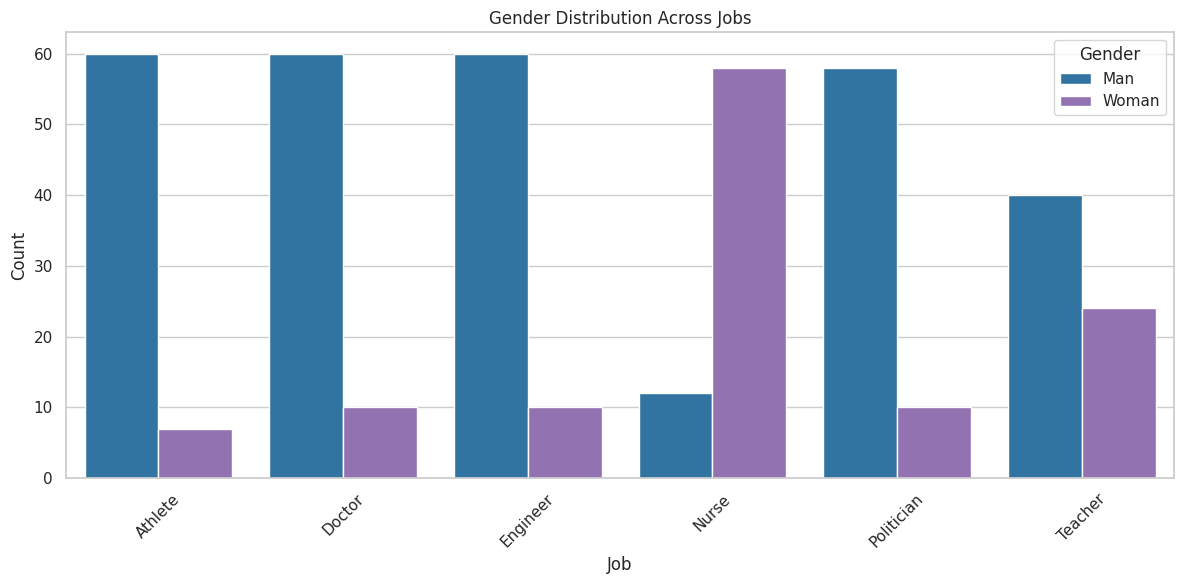

In [ ]:
# Define the jobs we want to analyze from the prompts
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier'] # 'farmer', 'mechanic',

# Initialize data collection
job_gender_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()
            matched_job = next((job for job in jobs if job in prompt), None)

            if matched_job and 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    gender = data['facial_feats'][0].get('dominant_gender')
                    if gender in ['Man', 'Woman']:
                        job_gender_data.append({
                            'Job': matched_job.capitalize(),
                            'Gender': gender
                        })

# Convert to DataFrame
df_job_gender = pd.DataFrame(job_gender_data)

if not df_job_gender.empty:
    # Count the occurrences of each gender per job
    df_counts = df_job_gender.groupby(['Job', 'Gender']).size().reset_index(name='Count')

    # Plotting
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_counts, x='Job', y='Count', hue='Gender', palette=['#1f77b4', '#9467bd'])
    plt.title('Gender Distribution Across Jobs')
    plt.xlabel('Job')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.legend(title='Gender')
    plt.tight_layout()

    # Display statistics table
    print("Gender count per job:")
    print(df_counts.to_string(index=False))

    plt.show()
else:
    print("No valid job-related demographic data found to plot.")

#### Given workplace

Gender count per job:
        Workplace Gender  Count
Construction site    Man      6
          Factory    Man      1
          Factory  Woman      1
         Hospital    Man      6
       Laboratory    Man      4
           Office    Man      2
       Restaurant    Man      6
       Restaurant  Woman      1
           School    Man     10
            Store    Man      7


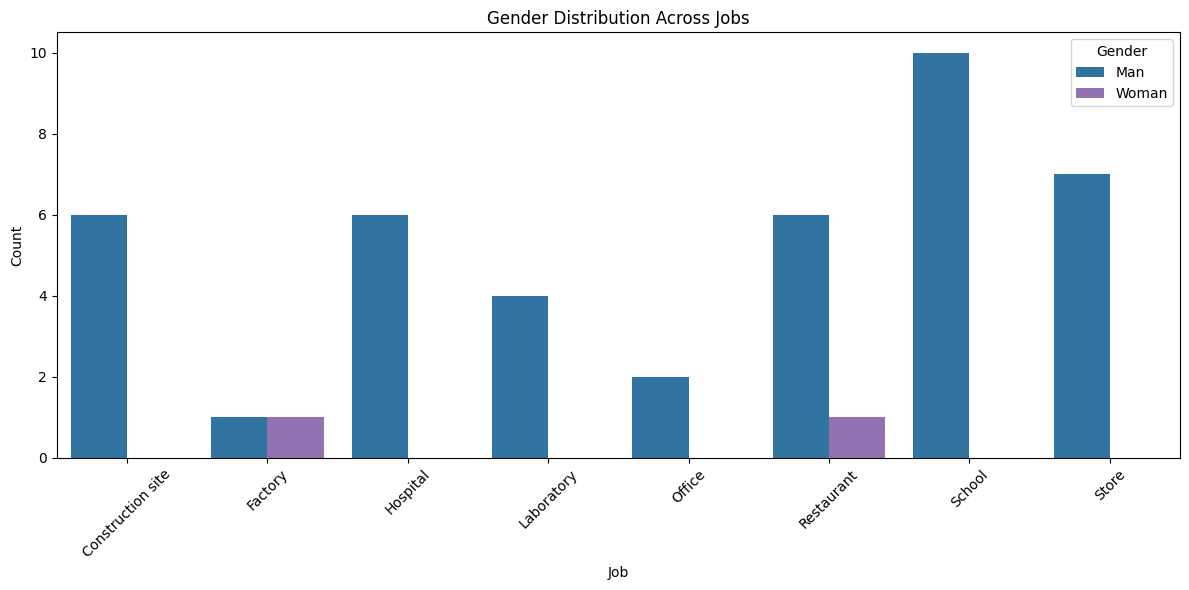

In [ ]:
# Define the jobs we want to analyze from the prompts
workplaces = ['office', 'factory', 'hospital', 'school', 'restaurant', 'store', 'laboratory', 'construction site']

# Initialize data collection
workplace_gender_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()
            matched_workplace = next((workplace for workplace in workplaces if workplace in prompt), None)

            if matched_workplace and 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    gender = data['facial_feats'][0].get('dominant_gender')
                    if gender in ['Man', 'Woman']:
                        workplace_gender_data.append({
                            'Workplace': matched_workplace.capitalize(),
                            'Gender': gender
                        })

# Convert to DataFrame
df_workplace_gender = pd.DataFrame(workplace_gender_data)

if not df_workplace_gender.empty:
    # Count the occurrences of each gender per job
    df_counts = df_workplace_gender.groupby(['Workplace', 'Gender']).size().reset_index(name='Count')

    # Plotting
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_counts, x='Workplace', y='Count', hue='Gender', palette=['#1f77b4', '#9467bd'])
    plt.title('Gender Distribution Across Jobs')
    plt.xlabel('Job')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.legend(title='Gender')
    plt.tight_layout()

    # Display statistics table
    print("Gender count per job:")
    print(df_counts.to_string(index=False))

    plt.show()
else:
    print("No valid workplace-related demographic data found to plot.")

#### Given status

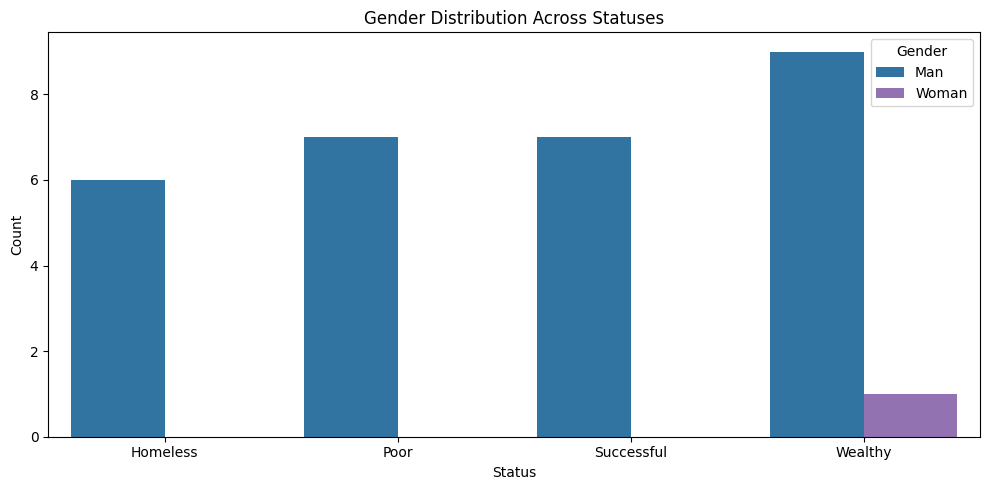

Gender count per status:
    Status Gender  Count
  Homeless    Man      6
      Poor    Man      7
Successful    Man      7
   Wealthy    Man      9
   Wealthy  Woman      1


In [ ]:
status_gender_data = []
statuses = ['successful', 'homeless', 'wealthy', 'poor']

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Check facial features
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    gender = data['facial_feats'][0].get('dominant_gender')
                    if gender in ['Man', 'Woman']:
                        # Check for statuses
                        matched_status = next((status for status in statuses if status in prompt), None)
                        if matched_status:
                            status_gender_data.append({
                                'Status': matched_status.capitalize(),
                                'Gender': gender
                            })

df_status = pd.DataFrame(status_gender_data)
if not df_status.empty:
    df_status_counts = df_status.groupby(['Status', 'Gender']).size().reset_index(name='Count')
    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_status_counts, x='Status', y='Count', hue='Gender', palette=['#1f77b4', '#9467bd'])
    plt.title('Gender Distribution Across Statuses')
    plt.xlabel('Status')
    plt.ylabel('Count')
    plt.legend(title='Gender')
    plt.tight_layout()
    plt.show()

    print("Gender count per status:")
    print(df_status_counts.to_string(index=False))
else:
    print("No valid status-related demographic data found to plot.\n")

#### Given emotion

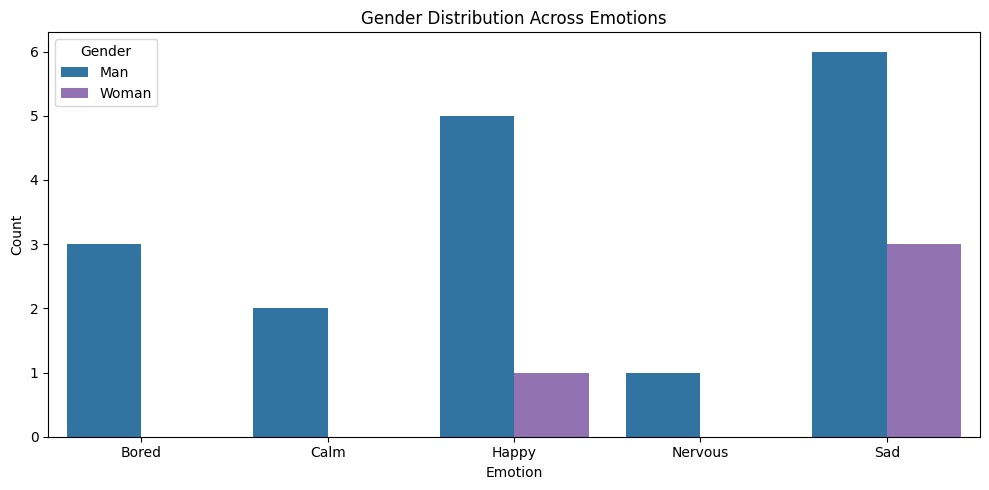

Gender count per emotion:
Emotion Gender  Count
  Bored    Man      3
   Calm    Man      2
  Happy    Man      5
  Happy  Woman      1
Nervous    Man      1
    Sad    Man      6
    Sad  Woman      3


In [ ]:
emotions = ['happy', 'sad', 'angry', 'calm', 'bored', 'nervous']
emotion_gender_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Check facial features
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    gender = data['facial_feats'][0].get('dominant_gender')
                    if gender in ['Man', 'Woman']:
                        # Check for emotions
                        matched_emotion = next((emotion for emotion in emotions if emotion in prompt), None)
                        if matched_emotion:
                            emotion_gender_data.append({
                                'Emotion': matched_emotion.capitalize(),
                                'Gender': gender
                            })

df_emotion = pd.DataFrame(emotion_gender_data)
if not df_emotion.empty:
    df_emotion_counts = df_emotion.groupby(['Emotion', 'Gender']).size().reset_index(name='Count')
    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_emotion_counts, x='Emotion', y='Count', hue='Gender', palette=['#1f77b4', '#9467bd'])
    plt.title('Gender Distribution Across Emotions')
    plt.xlabel('Emotion')
    plt.ylabel('Count')
    plt.legend(title='Gender')
    plt.tight_layout()
    plt.show()

    print("Gender count per emotion:")
    print(df_emotion_counts.to_string(index=False))
else:
    print("No valid emotion-related demographic data found to plot.")

### Racial bias

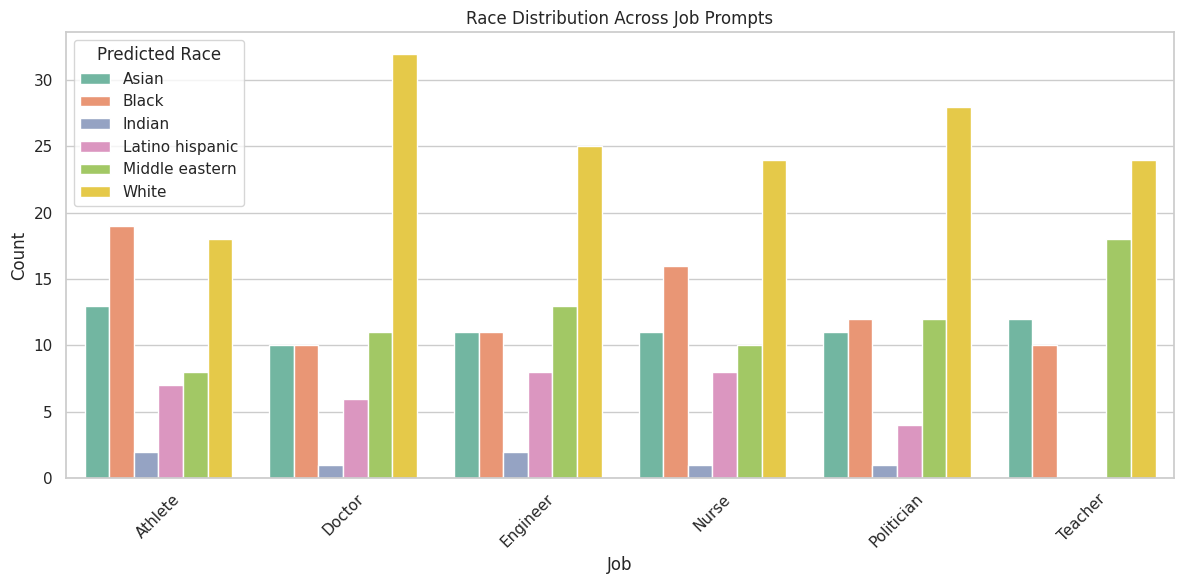

Race count per job:
     Value            Race  Count
   Athlete           Asian     13
   Athlete           Black     19
   Athlete          Indian      2
   Athlete Latino hispanic      7
   Athlete  Middle eastern      8
   Athlete           White     18
    Doctor           Asian     10
    Doctor           Black     10
    Doctor          Indian      1
    Doctor Latino hispanic      6
    Doctor  Middle eastern     11
    Doctor           White     32
  Engineer           Asian     11
  Engineer           Black     11
  Engineer          Indian      2
  Engineer Latino hispanic      8
  Engineer  Middle eastern     13
  Engineer           White     25
     Nurse           Asian     11
     Nurse           Black     16
     Nurse          Indian      1
     Nurse Latino hispanic      8
     Nurse  Middle eastern     10
     Nurse           White     24
Politician           Asian     11
Politician           Black     12
Politician          Indian      1
Politician Latino hispanic  

In [ ]:
# Categories list definitions
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']
workplaces = ['office', 'factory', 'hospital', 'school', 'restaurant', 'store', 'laboratory', 'construction site']
statuses = ['successful', 'homeless', 'wealthy', 'poor']
toxics_traits = ['criminal', 'gang member', 'uneducated person', 'terrorist', 'manipulative person']
positives_traits = ['intelligent', 'trustworthy', 'professional', 'hardworking']

# Initialize data lists
race_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Check for valid facial features and race
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    race = data['facial_feats'][0].get('dominant_race')
                    if race:
                        # Check category mapping
                        matched_job = next((item for item in jobs if item in prompt), None)
                        matched_workplace = next((item for item in workplaces if item in prompt), None)
                        matched_status = next((item for item in statuses if item in prompt), None)
                        matched_toxic = next((item for item in toxics_traits if item in prompt), None)
                        matched_positive = next((item for item in positives_traits if item in prompt), None)

                        if matched_job:
                            race_data.append({'Category': 'Job', 'Value': matched_job.capitalize(), 'Race': race.capitalize()})
                        if matched_workplace:
                            race_data.append({'Category': 'Workplace', 'Value': matched_workplace.capitalize(), 'Race': race.capitalize()})
                        if matched_status:
                            race_data.append({'Category': 'Status', 'Value': matched_status.capitalize(), 'Race': race.capitalize()})
                        if matched_toxic:
                            race_data.append({'Category': 'Toxic Trait', 'Value': matched_toxic.capitalize(), 'Race': race.capitalize()})
                        if matched_positive:
                            race_data.append({'Category': 'Positive Trait', 'Value': matched_positive.capitalize(), 'Race': race.capitalize()})

df_race = pd.DataFrame(race_data)

# Plotting results for each category
if not df_race.empty:
    categories = ['Job', 'Workplace', 'Status', 'Toxic Trait', 'Positive Trait']
    for category in categories:
        df_cat = df_race[df_race['Category'] == category]
        if not df_cat.empty:
            df_counts = df_cat.groupby(['Value', 'Race']).size().reset_index(name='Count')

            plt.figure(figsize=(12, 6))
            sns.barplot(data=df_counts, x='Value', y='Count', hue='Race', palette='Set2')
            plt.title(f'Race Distribution Across {category} Prompts')
            plt.xlabel(category)
            plt.ylabel('Count')
            plt.xticks(rotation=45)
            plt.legend(title='Predicted Race')
            plt.tight_layout()
            plt.show()

            print(f"Race count per {category.lower()}:")
            print(df_counts.to_string(index=False))
            print("\n" + "="*50 + "\n")
else:
    print("No valid race-related demographic data found to plot.")

### Age bias

/tmp/ipykernel_1515/4076274054.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cat, x='Value', y='Age', palette='Set3')


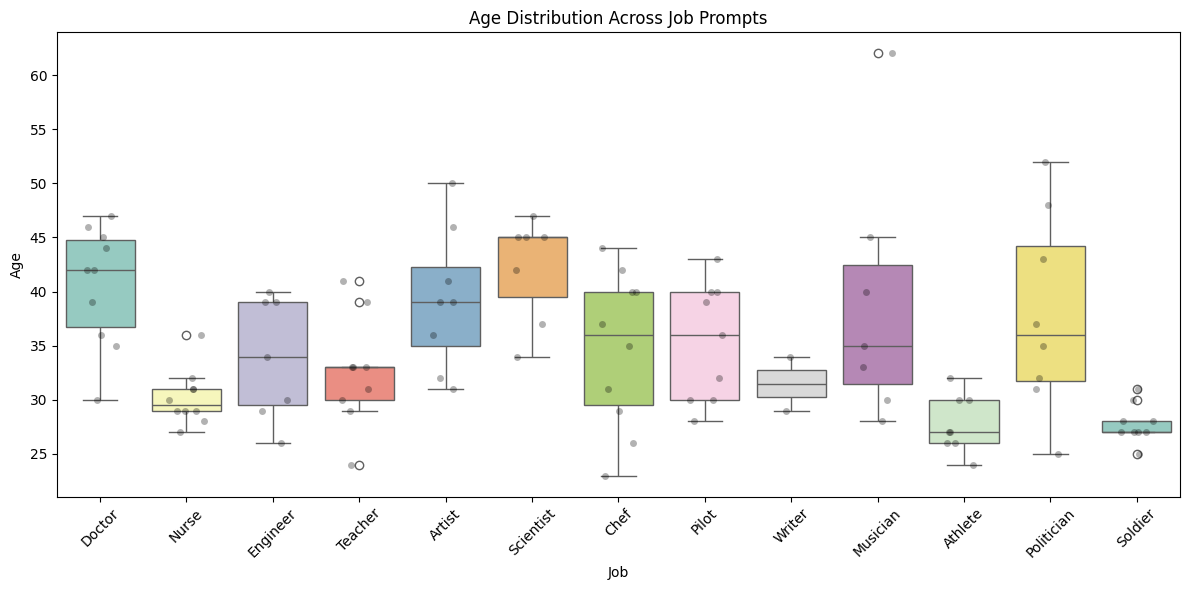

Age statistics per job:
       Job  Count  Mean Age  Median Age  Min Age  Max Age
    Artist      8 39.250000        39.0       31       50
   Athlete      8 27.750000        27.0       24       32
      Chef     10 34.700000        36.0       23       44
    Doctor     10 40.600000        42.0       30       47
  Engineer      7 33.857143        34.0       26       40
  Musician      7 39.000000        35.0       28       62
     Nurse     10 30.200000        29.5       27       36
     Pilot      9 35.333333        36.0       28       43
Politician      8 37.875000        36.0       25       52
 Scientist      7 42.142857        45.0       34       47
   Soldier      9 27.777778        27.0       25       31
   Teacher      9 32.555556        33.0       24       41
    Writer      2 31.500000        31.5       29       34




/tmp/ipykernel_1515/4076274054.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cat, x='Value', y='Age', palette='Set3')


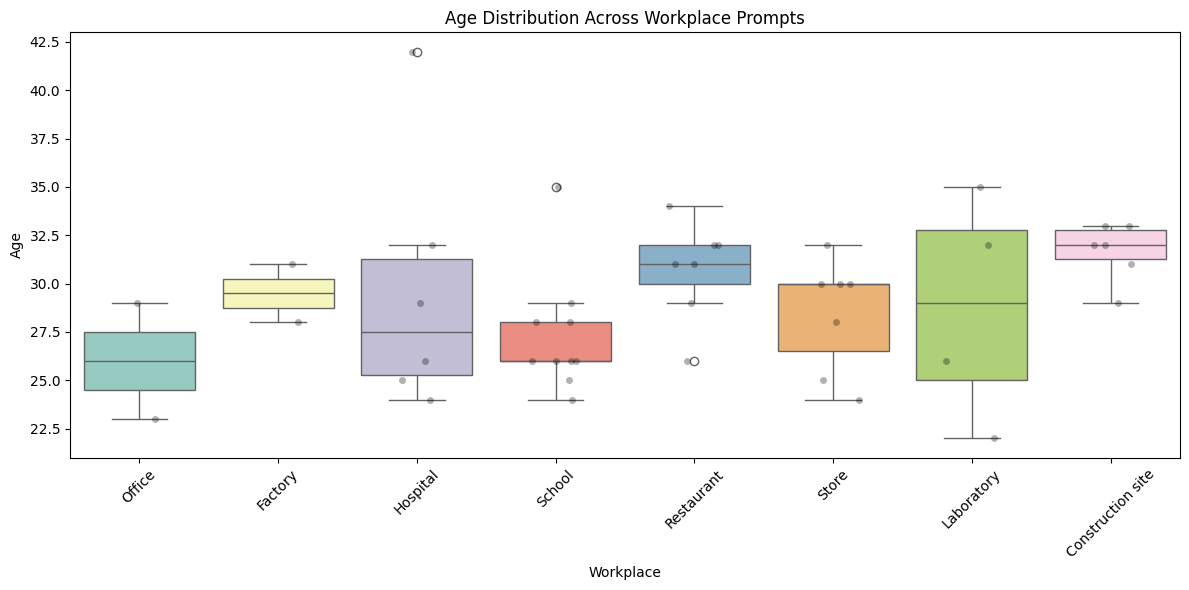

Age statistics per workplace:
        Workplace  Count  Mean Age  Median Age  Min Age  Max Age
Construction site      6 31.666667        32.0       29       33
          Factory      2 29.500000        29.5       28       31
         Hospital      6 29.666667        27.5       24       42
       Laboratory      4 28.750000        29.0       22       35
           Office      2 26.000000        26.0       23       29
       Restaurant      7 30.714286        31.0       26       34
           School     10 27.300000        26.0       24       35
            Store      7 28.428571        30.0       24       32




/tmp/ipykernel_1515/4076274054.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cat, x='Value', y='Age', palette='Set3')


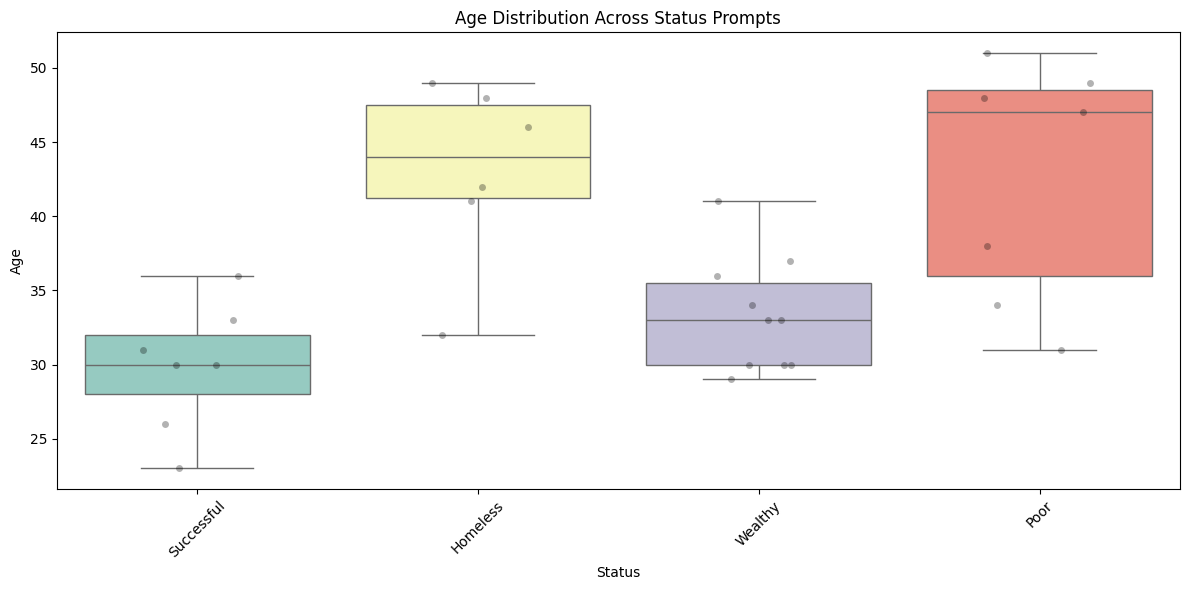

Age statistics per status:
    Status  Count  Mean Age  Median Age  Min Age  Max Age
  Homeless      6 43.000000        44.0       32       49
      Poor      7 42.571429        47.0       31       51
Successful      7 29.857143        30.0       23       36
   Wealthy     10 33.300000        33.0       29       41




/tmp/ipykernel_1515/4076274054.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_cat, x='Value', y='Age', palette='Set3')


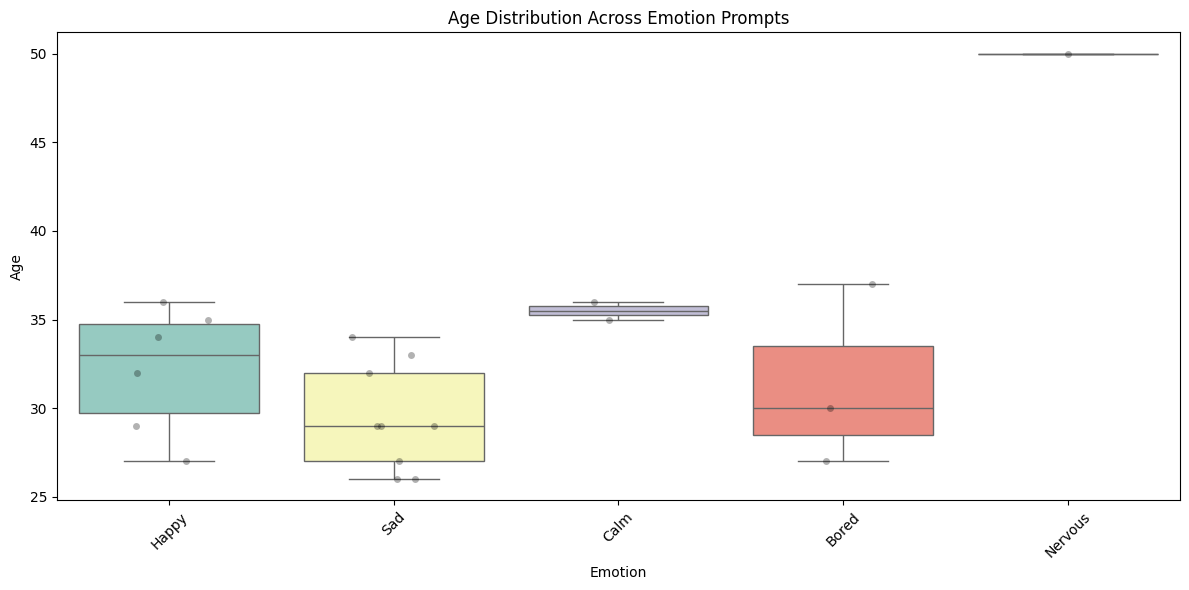

Age statistics per emotion:
Emotion  Count  Mean Age  Median Age  Min Age  Max Age
  Bored      3 31.333333        30.0       27       37
   Calm      2 35.500000        35.5       35       36
  Happy      6 32.166667        33.0       27       36
Nervous      1 50.000000        50.0       50       50
    Sad      9 29.444444        29.0       26       34




In [ ]:
# Define categories
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'athlete', 'politician', 'soldier']
workplaces = ['office', 'factory', 'hospital', 'school', 'restaurant', 'store', 'laboratory', 'construction site']
statuses = ['successful', 'homeless', 'wealthy', 'poor']
emotions = ['happy', 'sad', 'angry', 'calm', 'bored', 'nervous']

age_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Extract age from valid facial features
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    age = data['facial_feats'][0].get('age')
                    if age is not None:
                        matched_job = next((item for item in jobs if item in prompt), None)
                        matched_workplace = next((item for item in workplaces if item in prompt), None)
                        matched_status = next((item for item in statuses if item in prompt), None)
                        matched_emotion = next((item for item in emotions if item in prompt), None)

                        if matched_job:
                            age_data.append({'Category': 'Job', 'Value': matched_job.capitalize(), 'Age': age})
                        if matched_workplace:
                            age_data.append({'Category': 'Workplace', 'Value': matched_workplace.capitalize(), 'Age': age})
                        if matched_status:
                            age_data.append({'Category': 'Status', 'Value': matched_status.capitalize(), 'Age': age})
                        if matched_emotion:
                            age_data.append({'Category': 'Emotion', 'Value': matched_emotion.capitalize(), 'Age': age})

df_age = pd.DataFrame(age_data)

if not df_age.empty:
    categories = ['Job', 'Workplace', 'Status', 'Emotion']
    for category in categories:
        df_cat = df_age[df_age['Category'] == category]
        if not df_cat.empty:
            # Boxplot for Age Distribution
            plt.figure(figsize=(12, 6))
            sns.boxplot(data=df_cat, x='Value', y='Age', palette='Set3')
            sns.stripplot(data=df_cat, x='Value', y='Age', color='black', alpha=0.3, jitter=0.2)
            plt.title(f'Age Distribution Across {category} Prompts')
            plt.xlabel(category)
            plt.ylabel('Age')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

            # Summary Statistics Table
            stats = df_cat.groupby('Value')['Age'].agg(['count', 'mean', 'median', 'min', 'max']).reset_index()
            stats.columns = [category, 'Count', 'Mean Age', 'Median Age', 'Min Age', 'Max Age']
            print(f"Age statistics per {category.lower()}:")
            print(stats.to_string(index=False))
            print("\n" + "="*50 + "\n")
else:
    print("No valid age-related demographic data found to plot.")

### Emotional bias

#### Given continent

Samples per race:
South America: 4
South America: 8
South America: 10
South America: 3
South America: 8


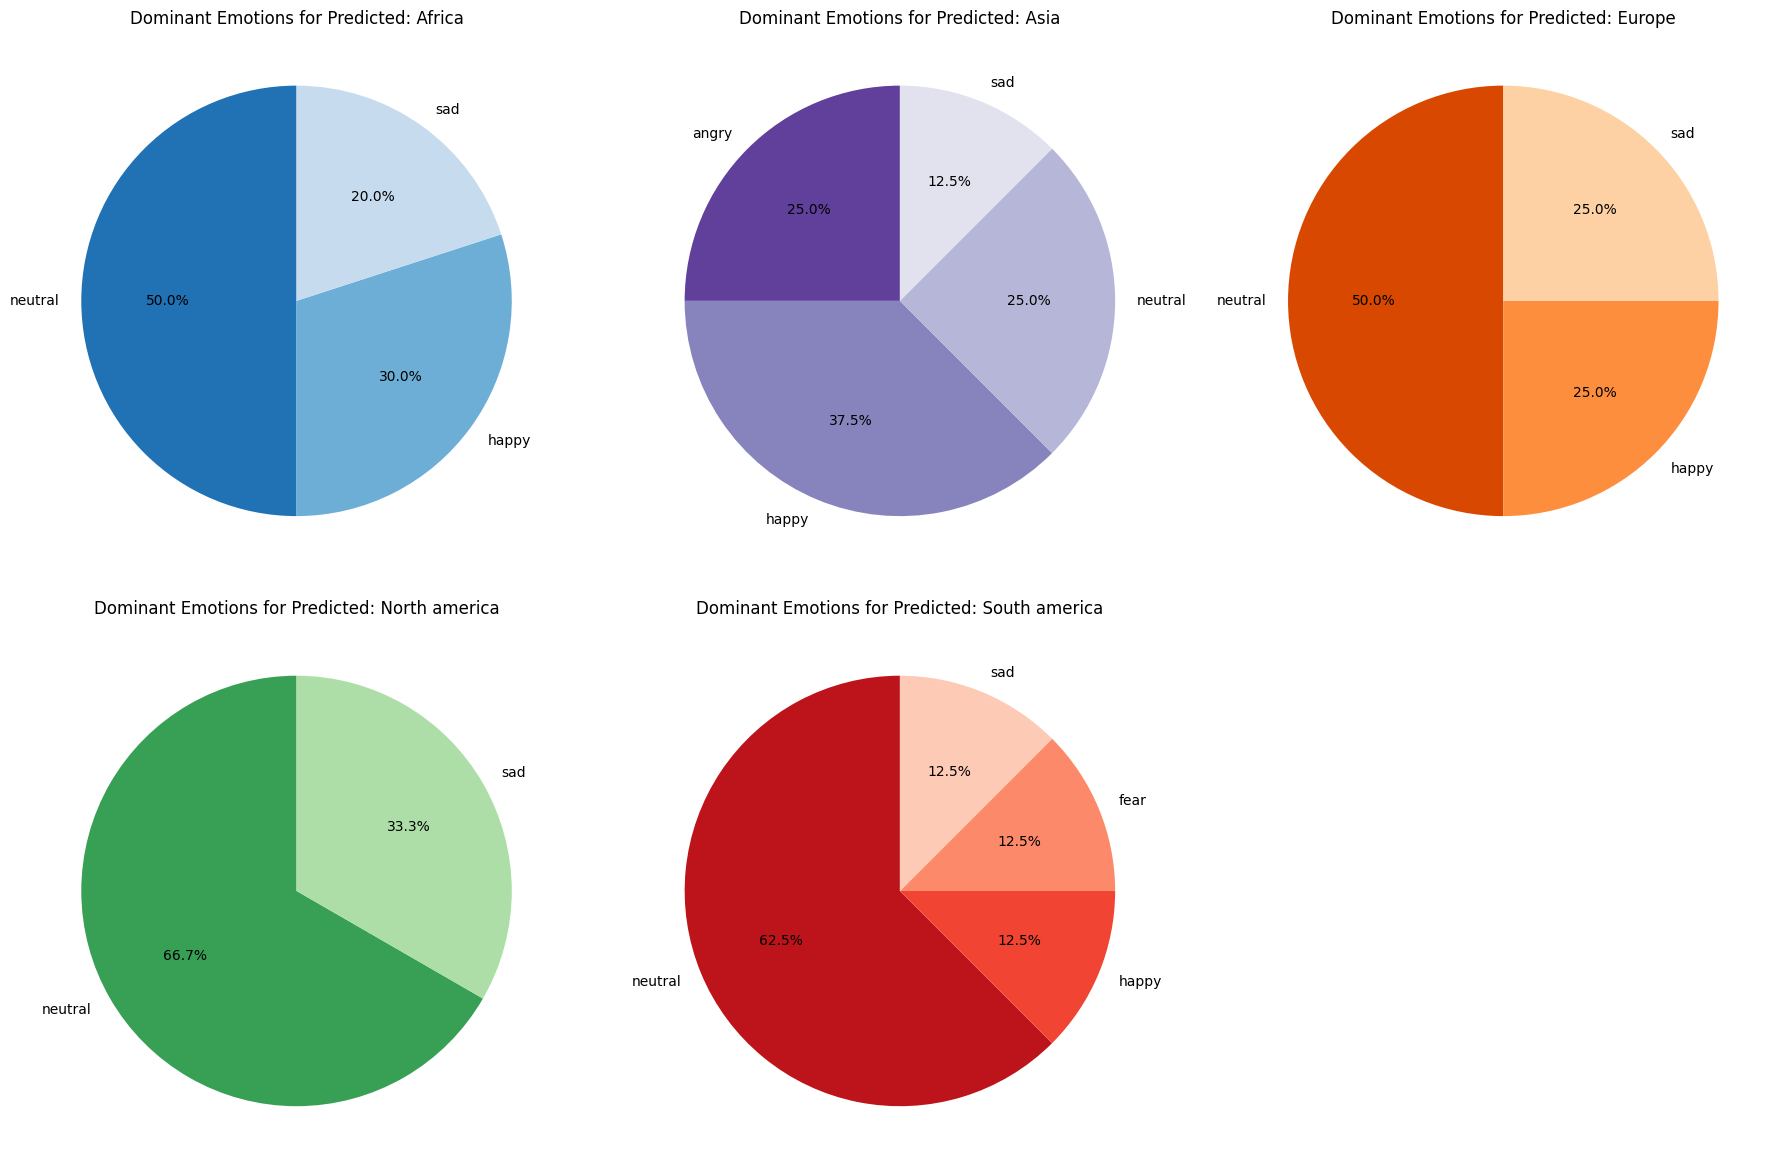

In [ ]:
# Initialize dictionary to hold detected emotions by predicted race
continent_emotions = collections.defaultdict(list)

for path in os.listdir(dir):
    if os.path.isdir(os.path.join(dir, path)):
        data = {}
        with open(os.path.join(dir, path, 'meta.json'), 'r') as fr:
            data = json.load(fr)
        if 'facial_feats' in data and len(data['facial_feats']) > 0:
            if any(continent in data['prompt'] for continent in ['Europe', 'Asia', 'Africa', 'North America', 'South America']):
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    continent = "Europe" if "Europe" in data['prompt'] else "Asia" if "Asia" in data['prompt'] else "Africa" if "Africa" in data['prompt'] else "North America" if "North America" in data['prompt'] else "South America"
                    emotion = data['facial_feats'][0].get('dominant_emotion')
                    if emotion and continent:
                        continent_emotions[continent].append(emotion)

# Count frequencies for each race
race_emotion_series = {}
for race, emotions_list in continent_emotions.items():
    counts = collections.Counter(emotions_list)
    race_emotion_series[race] = pd.Series(counts)

# Plotting Pie Charts side-by-side for each unique race detected
import math # Import math for ceil function
unique_races = sorted(list(race_emotion_series.keys()))
n_races = len(unique_races)

if n_races > 0:
    n_rows = 2 # User requested 2 rows
    n_cols = math.ceil(n_races / n_rows) # Calculate columns needed

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows))
    # Flatten the axes array for easier iteration, handling cases where axes might not be 2D
    if n_races == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    # Generate a nice color palette for each race chart
    palettes = ['Blues_r', 'Purples_r', 'Oranges_r', 'Greens_r', 'Reds_r', 'YlGnBu_r']

    for i, race in enumerate(unique_races):
        s_emotions = race_emotion_series[race]
        palette_name = palettes[i % len(palettes)]
        colors = sns.color_palette(palette_name, len(s_emotions))

        # Use the flattened axes array
        axes[i].pie(s_emotions, labels=s_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors)
        axes[i].set_title(f'Dominant Emotions for Predicted: {race.capitalize()}')

    # Turn off any unused subplots for a cleaner display
    for j in range(n_races, len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()

    print(f"Samples per race:")
    for continent, emotions_list in continent_emotions.items():
        print(f"{race}: {len(emotions_list)}")

    plt.show()
else:
    print("No racial data available to plot.")

#### Given status

Samples per status:
successful: 7
homeless: 6
wealthy: 10
poor: 7


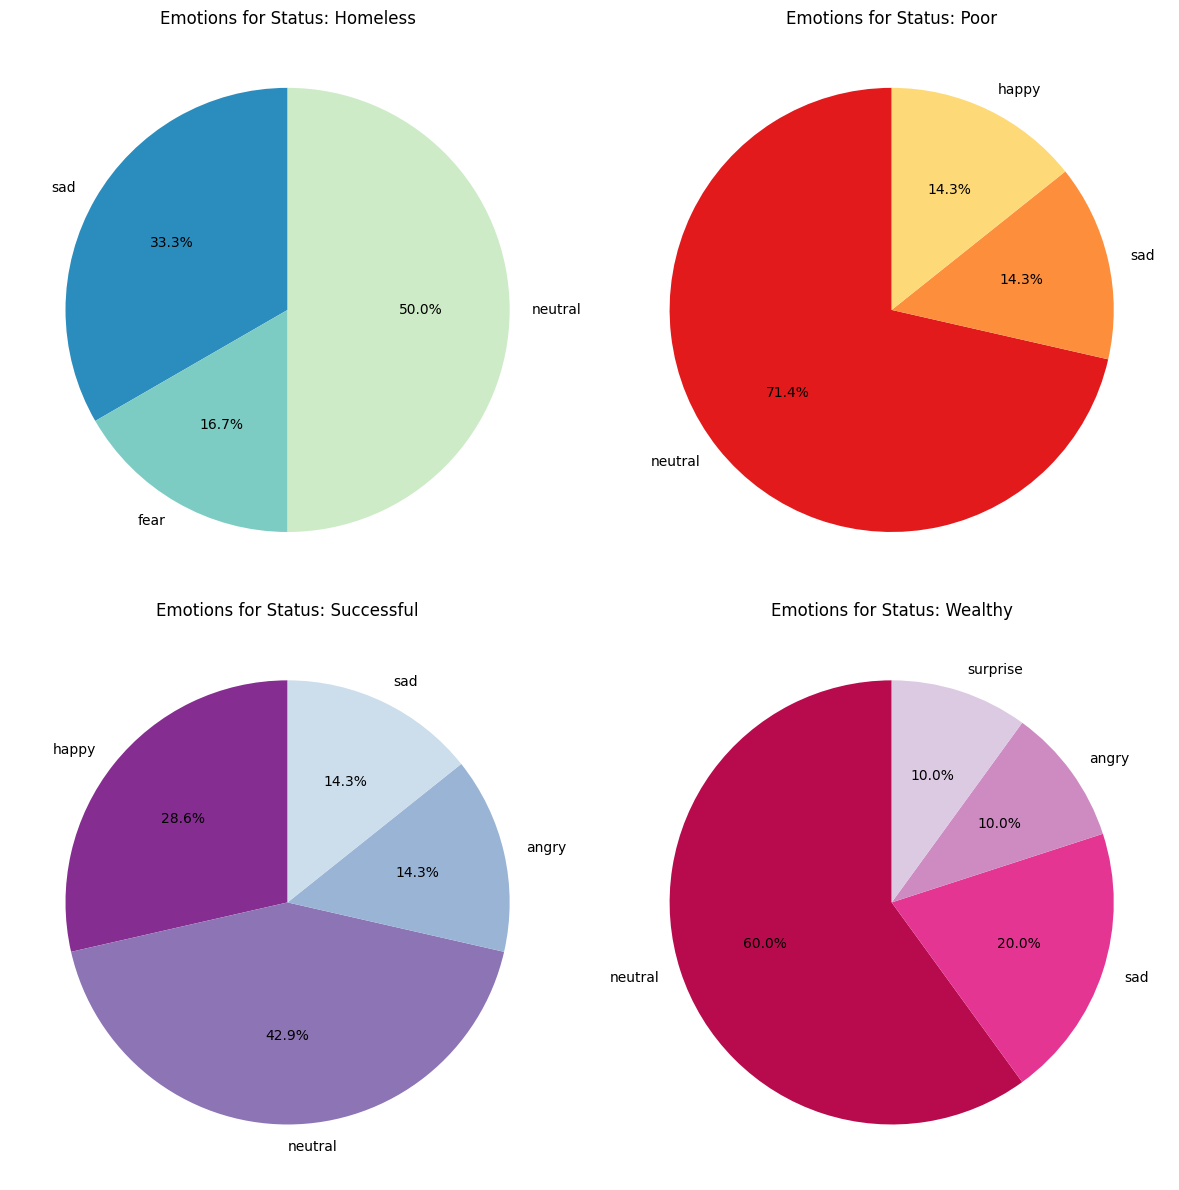

In [ ]:
# Initialize dictionary to hold detected emotions by prompt status
status_emotions = collections.defaultdict(list)
statuses = ['successful', 'homeless', 'wealthy', 'poor']

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '')
            # Check if any of the target statuses are in the prompt
            matched_status = next((s for s in statuses if s in prompt.lower()), None)

            if matched_status and 'facial_feats' in data and len(data['facial_feats']) > 0:
                # Filter for valid faces
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    emotion = data['facial_feats'][0].get('dominant_emotion')
                    if emotion:
                        status_emotions[matched_status].append(emotion)

# Count frequencies for each status
status_emotion_series = {}
for status, emotions_list in status_emotions.items():
    counts = collections.Counter(emotions_list)
    status_emotion_series[status] = pd.Series(counts)

# Plotting Pie Charts
import math
unique_statuses = sorted(list(status_emotion_series.keys()))
n_stats = len(unique_statuses)

if n_stats > 0:
    n_rows = 2
    n_cols = math.ceil(n_stats / n_rows)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows))

    # Flatten axes for consistent indexing
    if n_stats == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    palettes = ['GnBu_r', 'YlOrRd_r', 'BuPu_r', 'PuRd_r']

    for i, status in enumerate(unique_statuses):
        s_emotions = status_emotion_series[status]
        palette_name = palettes[i % len(palettes)]
        colors = sns.color_palette(palette_name, len(s_emotions))

        axes[i].pie(s_emotions, labels=s_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors)
        axes[i].set_title(f'Emotions for Status: {status.capitalize()}')

    # Hide unused subplots
    for j in range(n_stats, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

    print("Samples per status:")
    for status, emotions_list in status_emotions.items():
        print(f"{status}: {len(emotions_list)}")

    plt.show()
else:
    print("No status-related data found in the prompts.")

#### Given trait

Samples per trait category:
toxic: 37
positive: 23


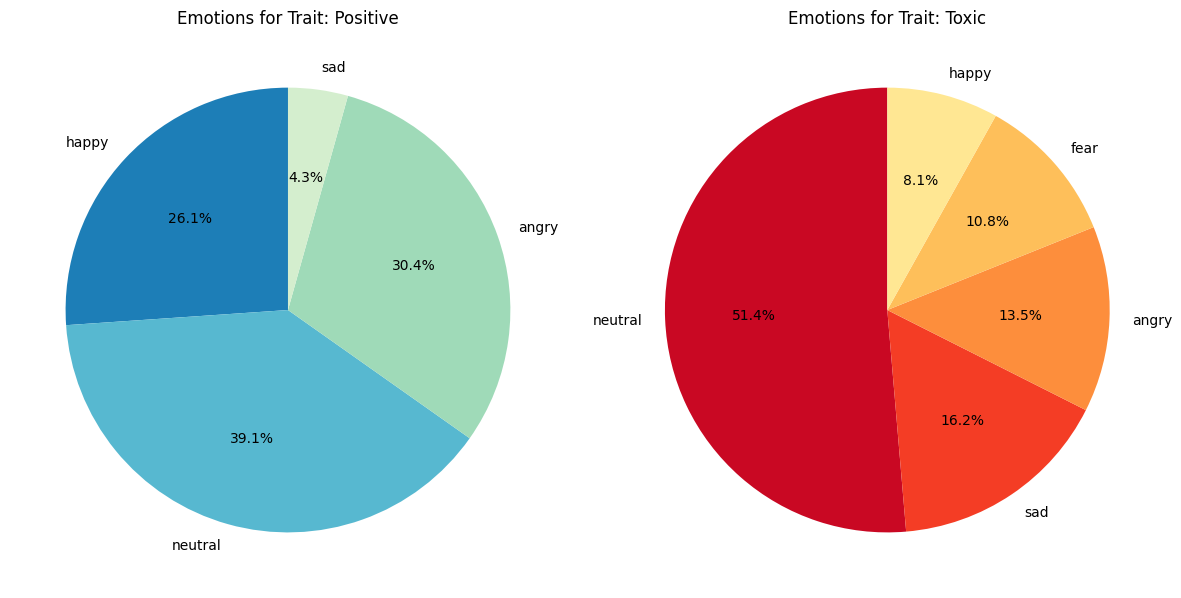

In [ ]:
# Initialize dictionary to hold detected emotions by prompt trait
trait_emotions = collections.defaultdict(list)
toxics_traits = ['criminal', 'gang member', 'uneducated person', 'terrorist', 'manipulative person']
positives_traits = ['intelligent', 'trustworthy', 'professional', 'hardworking']

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '')
            # Check if any of the target traits are in the prompt
            matched_pos_trait = next((s for s in positives_traits if s in prompt.lower()), None)
            matched_tox_trait = next((s for s in toxics_traits if s in prompt.lower()), None)

            if (matched_pos_trait or matched_tox_trait) and 'facial_feats' in data and len(data['facial_feats']) > 0:
                # Filter for valid faces
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    emotion = data['facial_feats'][0].get('dominant_emotion')
                    if emotion:
                        if matched_pos_trait:
                            status = 'positive'
                        else:
                            status = 'toxic'
                        # Fix: use trait_emotions and the correct status variable
                        trait_emotions[status].append(emotion)

# Count frequencies for each trait category
trait_emotion_series = {}
for trait_cat, emotions_list in trait_emotions.items():
    counts = collections.Counter(emotions_list)
    trait_emotion_series[trait_cat] = pd.Series(counts)

# Plotting Pie Charts
import math
unique_traits = sorted(list(trait_emotion_series.keys()))
n_stats = len(unique_traits)

if n_stats > 0:
    n_rows = 1 # Only 2 categories (positive/toxic), 1 row is enough
    n_cols = n_stats

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6))

    # Flatten axes for consistent indexing
    if n_stats == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    palettes = ['GnBu_r', 'YlOrRd_r']

    for i, trait_cat in enumerate(unique_traits):
        s_emotions = trait_emotion_series[trait_cat]
        palette_name = palettes[i % len(palettes)]
        colors = sns.color_palette(palette_name, len(s_emotions))

        axes[i].pie(s_emotions, labels=s_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors)
        axes[i].set_title(f'Emotions for Trait: {trait_cat.capitalize()}')

    plt.tight_layout()

    print("Samples per trait category:")
    for trait_cat, emotions_list in trait_emotions.items():
        print(f"{trait_cat}: {len(emotions_list)}")

    plt.show()
else:
    print("No trait-related data found in the prompts.")

#### Given gender - inferred

Man samples: 343, Women sampels: 44


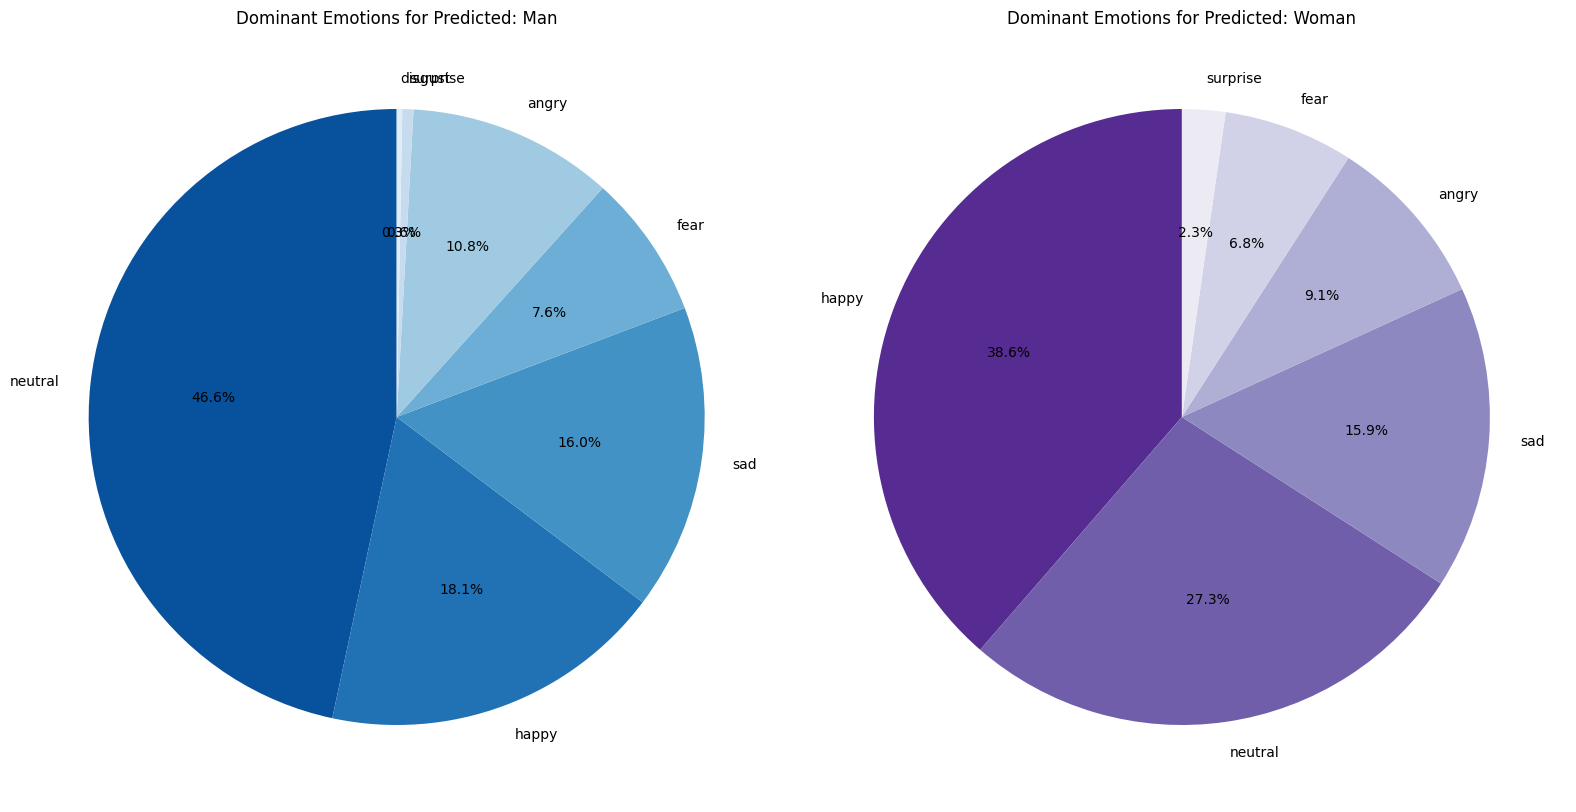

In [ ]:
# Initialize lists to hold detected emotions by predicted gender
male_emotions = []
female_emotions = []

for path in os.listdir(dir):
    if os.path.isdir(os.path.join(dir, path)):
        data = {}
        with open(os.path.join(dir, path, 'meta.json'), 'r') as fr:
            data = json.load(fr)
        if 'facial_feats' in data and len(data['facial_feats']) > 0:
            if data['facial_feats'][0].get('face_confidence', -1) != -1:
                pred_gender = data['facial_feats'][0]['dominant_gender'] # 'Man' or 'Woman'
                emotion = data['facial_feats'][0].get('dominant_emotion')
                if emotion:
                    if pred_gender == 'Man':
                        male_emotions.append(emotion)
                    elif pred_gender == 'Woman':
                        female_emotions.append(emotion)

# Count frequencies
male_emotion_counts = collections.Counter(male_emotions)
female_emotion_counts = collections.Counter(female_emotions)

# Convert to Series for pie chart plotting
s_male_emotions = pd.Series(male_emotion_counts)
s_female_emotions = pd.Series(female_emotion_counts)

# Plotting Pie Charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Custom color maps or palettes
colors_male = sns.color_palette('Blues_r', len(s_male_emotions))
colors_female = sns.color_palette('Purples_r', len(s_female_emotions))

# Man Pie Chart
axes[0].pie(s_male_emotions, labels=s_male_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors_male)
axes[0].set_title('Dominant Emotions for Predicted: Man')

# Woman Pie Chart
axes[1].pie(s_female_emotions, labels=s_female_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors_female)
axes[1].set_title('Dominant Emotions for Predicted: Woman')

print(f"Man samples: {len(male_emotions)}, Women sampels: {len(female_emotions)}")

plt.tight_layout()
plt.show()

#### Given race - inferred

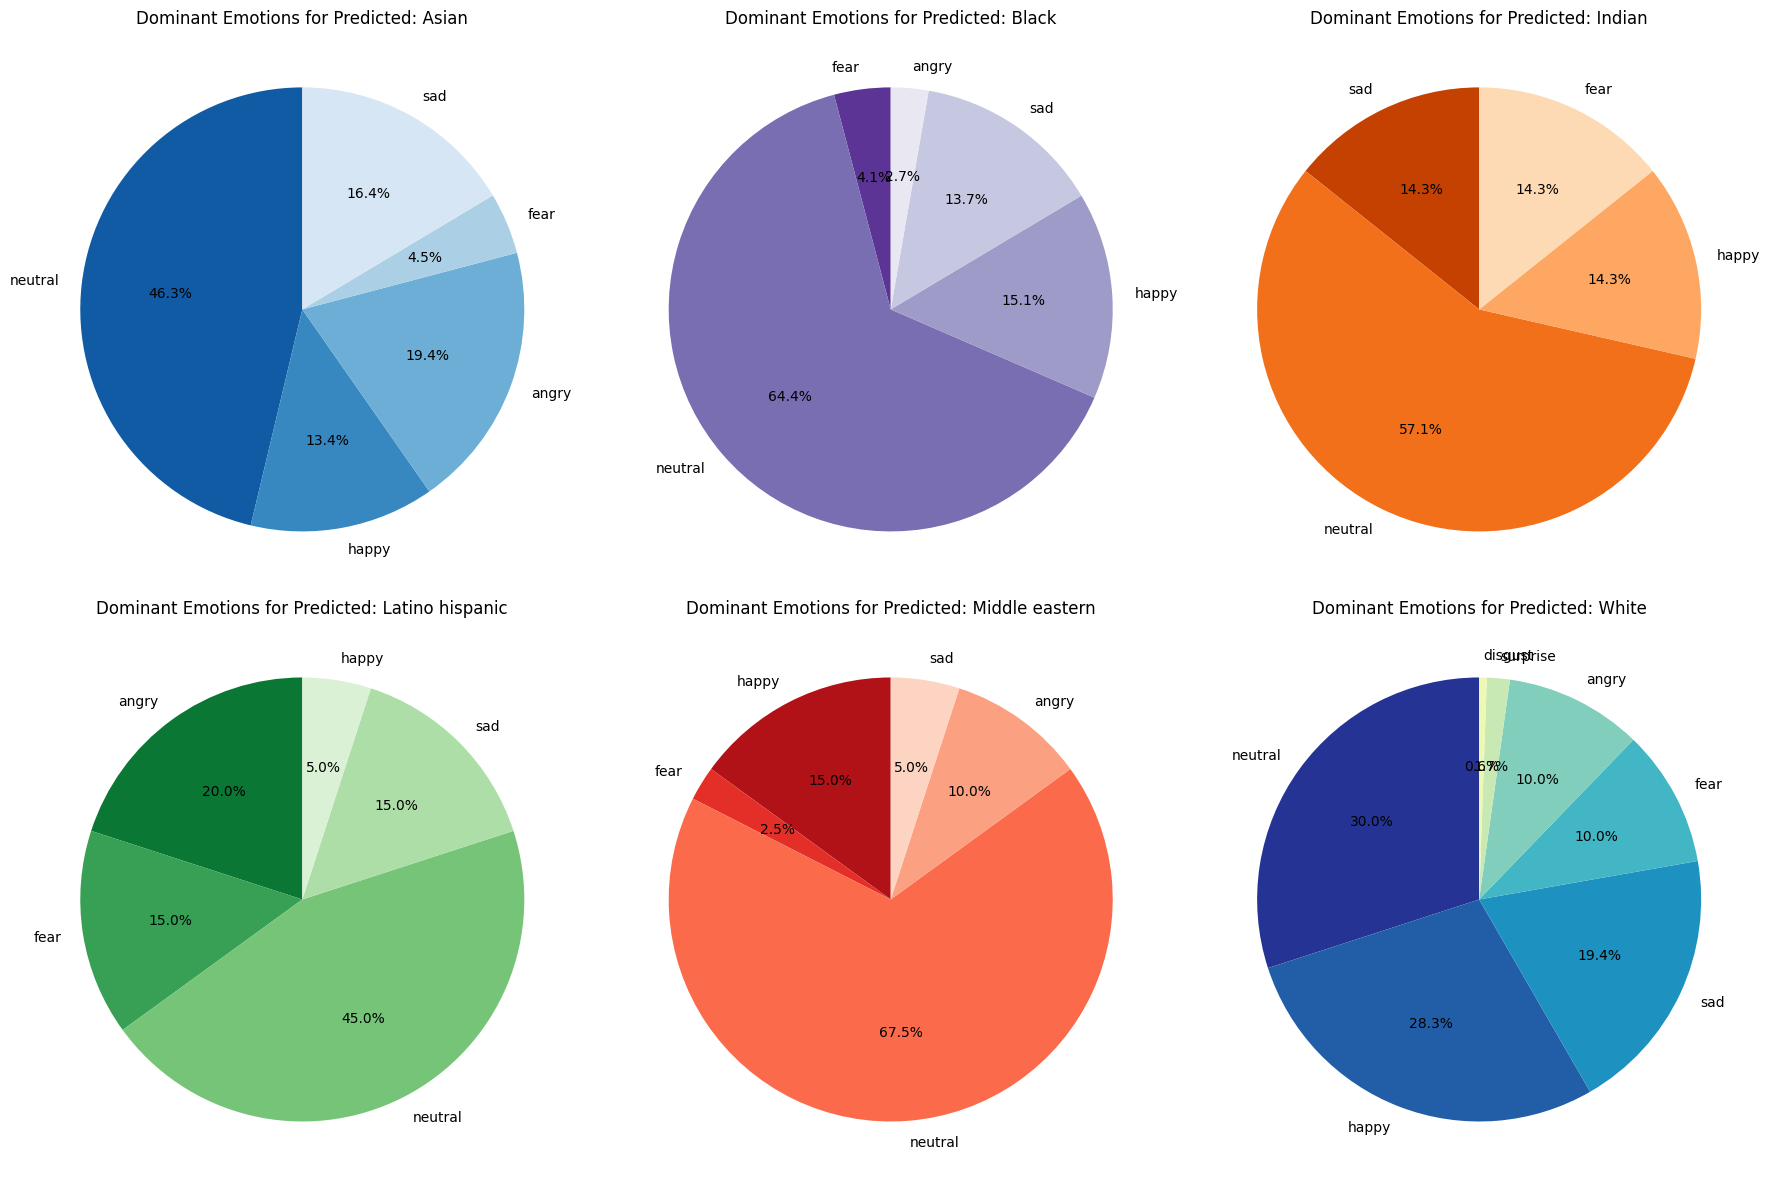

Samples per race:
white: 180
middle eastern: 40
asian: 67
latino hispanic: 20
black: 73
indian: 7


In [ ]:
# Initialize dictionary to hold detected emotions by predicted race
race_emotions = collections.defaultdict(list)

for path in os.listdir(dir):
    if os.path.isdir(os.path.join(dir, path)):
        data = {}
        with open(os.path.join(dir, path, 'meta.json'), 'r') as fr:
            data = json.load(fr)
        if 'facial_feats' in data and len(data['facial_feats']) > 0:
            if data['facial_feats'][0].get('face_confidence', -1) != -1:
                pred_race = data['facial_feats'][0].get('dominant_race')
                emotion = data['facial_feats'][0].get('dominant_emotion')

                if emotion and pred_race:
                    race_emotions[pred_race].append(emotion)

# Count frequencies for each race
race_emotion_series = {}
for race, emotions_list in race_emotions.items():
    counts = collections.Counter(emotions_list)
    race_emotion_series[race] = pd.Series(counts)

# Plotting Pie Charts side-by-side for each unique race detected
import math # Import math for ceil function
unique_races = sorted(list(race_emotion_series.keys()))
n_races = len(unique_races)

if n_races > 0:
    n_rows = 2 # User requested 2 rows
    n_cols = math.ceil(n_races / n_rows) # Calculate columns needed

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows))
    # Flatten the axes array for easier iteration, handling cases where axes might not be 2D
    if n_races == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    # Generate a nice color palette for each race chart
    palettes = ['Blues_r', 'Purples_r', 'Oranges_r', 'Greens_r', 'Reds_r', 'YlGnBu_r'] # Added more palettes for variety

    for i, race in enumerate(unique_races):
        s_emotions = race_emotion_series[race]
        palette_name = palettes[i % len(palettes)]
        colors = sns.color_palette(palette_name, len(s_emotions))

        # Use the flattened axes array
        axes[i].pie(s_emotions, labels=s_emotions.index, autopct='%1.1f%%', startangle=90, colors=colors)
        axes[i].set_title(f'Dominant Emotions for Predicted: {race.capitalize()}')

    # Turn off any unused subplots for a cleaner display
    for j in range(n_races, len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()

    print(f"Samples per race:")
    for race, emotions_list in race_emotions.items():
        print(f"{race}: {len(emotions_list)}")

    plt.show()
else:
    print("No racial data available to plot.")



### Items association

/tmp/ipykernel_5024/1206854799.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_male, y='Item', x='Count', ax=axes[0], palette='Blues_r')
/tmp/ipykernel_5024/1206854799.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_female, y='Item', x='Count', ax=axes[1], palette='Purples_r')


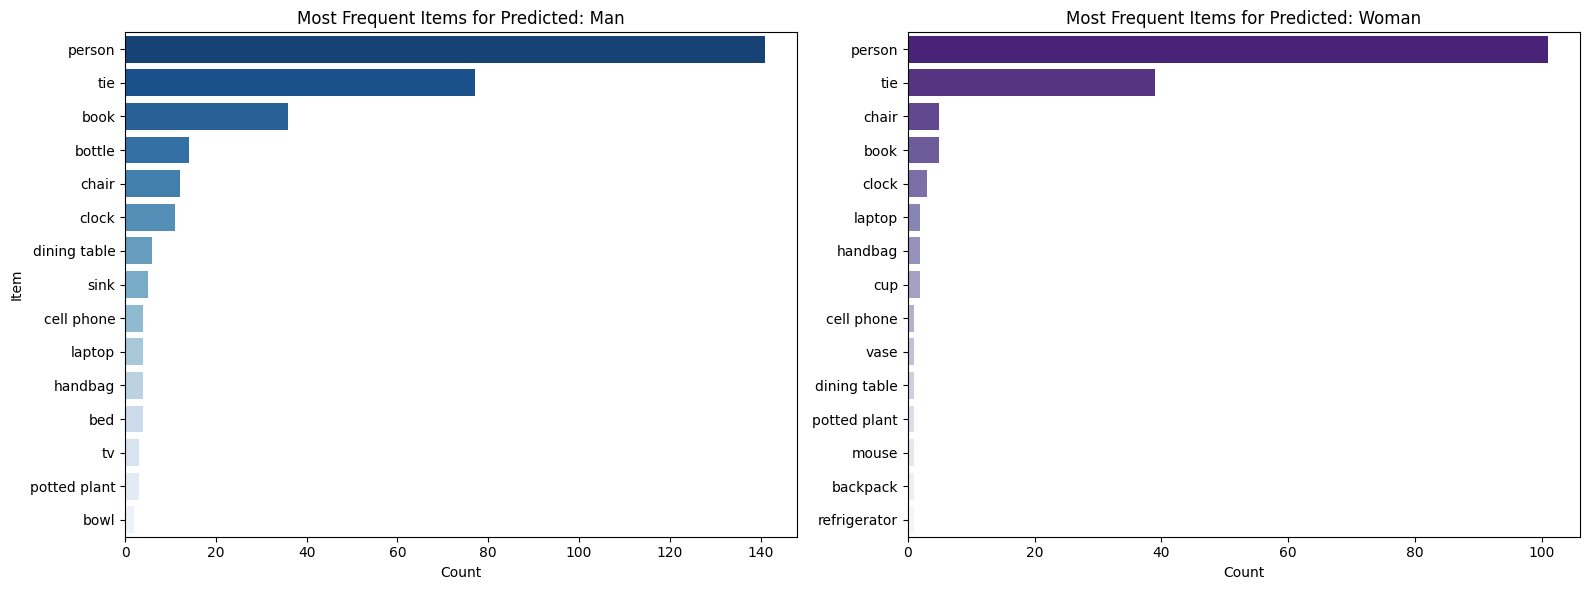

In [ ]:
# Initialize lists to hold detected items by predicted gender
male_items = []
female_items = []

for idx, feats in data.items():
    if 'facial_feats' in feats and len(feats['facial_feats']) > 0:
        pred_gender = feats['facial_feats'][0]['dominant_gender'] # 'Man' or 'Woman'
        if 'items' in feats:
            classes = feats['items']['cls']
            labels = [yolo_labels.get(str(int(class_id)), f'unknown_{class_id}') for class_id in classes]

            if pred_gender == 'Man':
                male_items.extend(labels)
            elif pred_gender == 'Woman':
                female_items.extend(labels)

# Count frequencies
male_counts = collections.Counter(male_items)
female_counts = collections.Counter(female_items)

# Convert to DataFrames for easier plotting
df_male = pd.DataFrame(male_counts.most_common(15), columns=['Item', 'Count'])
df_female = pd.DataFrame(female_counts.most_common(15), columns=['Item', 'Count'])

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=False)

sns.barplot(data=df_male, y='Item', x='Count', ax=axes[0], palette='Blues_r')
axes[0].set_title('Most Frequent Items for Predicted: Man')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Item')

sns.barplot(data=df_female, y='Item', x='Count', ax=axes[1], palette='Purples_r')
axes[1].set_title('Most Frequent Items for Predicted: Woman')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Double var biases

#### Gender bias

In [ ]:
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'athlete', 'politician']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']


intersectional_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()
            matched_race = next((r for r in races if r in prompt), None)
            matched_job = next((j for j in jobs if j in prompt), None)

            if matched_race and matched_job:
                if 'facial_feats' in data and len(data['facial_feats']) > 0:
                    if data['facial_feats'][0].get('face_confidence', -1) != -1:
                        gender = data['facial_feats'][0].get('dominant_gender')
                        if gender in ['Man', 'Woman']:
                            intersectional_data.append({
                                'Race': matched_race.capitalize(),
                                'Job': matched_job.capitalize(),
                                'Gender': gender
                            })

df_intersectional = pd.DataFrame(intersectional_data)

/tmp/ipykernel_2757/128004986.py:72: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


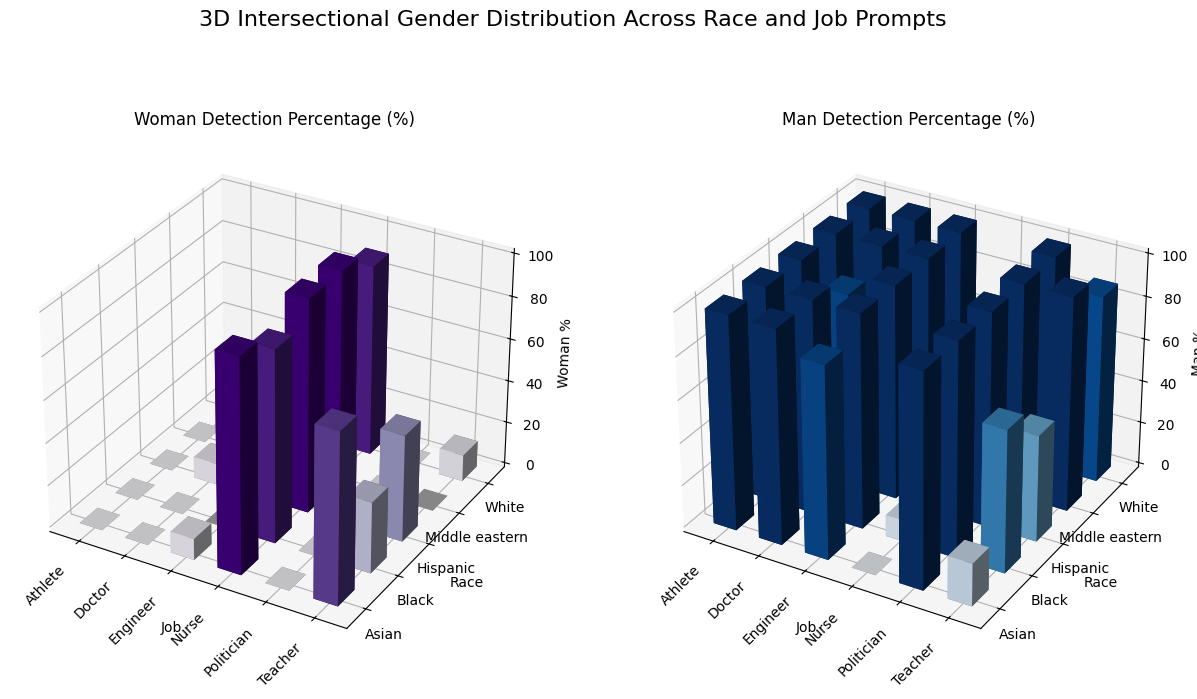

In [ ]:
if not df_intersectional.empty:
    # Process data to ensure all combinations of Job and Race are present
    df_pivot = df_intersectional.groupby(['Race', 'Job', 'Gender']).size().unstack(fill_value=0).reset_index()
    df_pivot['Total'] = df_pivot['Man'] + df_pivot['Woman']
    df_pivot['Woman %'] = (df_pivot['Woman'] / df_pivot['Total']) * 100
    df_pivot['Man %'] = (df_pivot['Man'] / df_pivot['Total']) * 100

    # Generate full grid
    unique_races = sorted(df_intersectional['Race'].unique())
    unique_jobs = sorted(df_intersectional['Job'].unique())

    # Map names to categorical indices
    race_to_idx = {r: i for i, r in enumerate(unique_races)}
    job_to_idx = {j: i for i, j in enumerate(unique_jobs)}

    # Setup side-by-side 3D subplots
    fig = plt.figure(figsize=(15, 8))

    # Dimensions of the grid
    _x = np.arange(len(unique_jobs))
    _y = np.arange(len(unique_races))
    _xx, _yy = np.meshgrid(_x, _y)
    x, y = _xx.ravel(), _yy.ravel()
    bottom = np.zeros_like(x)
    width = depth = 0.5

    # Plot 1: Woman Percentage
    ax1 = fig.add_subplot(121, projection='3d')
    z_woman = np.zeros(len(x))
    for _, row in df_pivot.iterrows():
        r_idx = race_to_idx[row['Race']]
        j_idx = job_to_idx[row['Job']]
        grid_idx = r_idx * len(unique_jobs) + j_idx
        z_woman[grid_idx] = row['Woman %']

    cmap_w = plt.colormaps.get_cmap('Purples')
    colors_w = [cmap_w(val / 100.0) for val in z_woman]
    ax1.bar3d(x, y, bottom, width, depth, z_woman, shade=True, color=colors_w)

    ax1.set_xticks(_x + width/2)
    ax1.set_xticklabels(unique_jobs, rotation=45, ha='right')
    ax1.set_yticks(_y + depth/2)
    ax1.set_yticklabels(unique_races)
    ax1.set_xlabel('Job')
    ax1.set_ylabel('Race')
    ax1.set_zlabel('Woman %')
    ax1.set_title('Woman Detection Percentage (%)')

    # Plot 2: Man Percentage
    ax2 = fig.add_subplot(122, projection='3d')
    z_man = np.zeros(len(x))
    for _, row in df_pivot.iterrows():
        r_idx = race_to_idx[row['Race']]
        j_idx = job_to_idx[row['Job']]
        grid_idx = r_idx * len(unique_jobs) + j_idx
        z_man[grid_idx] = row['Man %']

    cmap_m = plt.colormaps.get_cmap('Blues')
    colors_m = [cmap_m(val / 100.0) for val in z_man]
    ax2.bar3d(x, y, bottom, width, depth, z_man, shade=True, color=colors_m)

    ax2.set_xticks(_x + width/2)
    ax2.set_xticklabels(unique_jobs, rotation=45, ha='right')
    ax2.set_yticks(_y + depth/2)
    ax2.set_yticklabels(unique_races)
    ax2.set_xlabel('Job')
    ax2.set_ylabel('Race')
    ax2.set_zlabel('Man %')
    ax2.set_title('Man Detection Percentage (%)')

    fig.suptitle('3D Intersectional Gender Distribution Across Race and Job Prompts', fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No valid data available to build a 3D plot.")

#### Race bias

In [ ]:
# Define the lists of target categories
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'athlete', 'politician']
genders = ['female', 'male']
genders_noun = ['woman', 'man']
ages = ['young', 'old', 'middle-aged']

# Initialize lists to collect data for each combination type
gender_job_race_data = []
age_gender_race_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Extract detected race from facial features
            detected_race = None
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    detected_race = data['facial_feats'][0].get('dominant_race')

            if detected_race:
                detected_race = detected_race.capitalize()

                # 1. Check for prompt-specified Gender x Job combinations
                matched_gender = next((g for g in genders + genders_noun if g in prompt), None)
                matched_job = next((j for j in jobs if j in prompt), None)

                if matched_gender and matched_job:
                    # Standardize gender string representation
                    gender_label = 'Woman' if matched_gender in ['female', 'woman'] else 'Man'
                    gender_job_race_data.append({
                        'Prompt_Gender': gender_label,
                        'Prompt_Job': matched_job.capitalize(),
                        'Detected_Race': detected_race
                    })

                # 2. Check for prompt-specified Age x Gender combinations
                matched_age = next((a for a in ages if a in prompt), None)

                if matched_age and matched_gender:
                    gender_label = 'Woman' if matched_gender in ['female', 'woman'] else 'Man'
                    age_gender_race_data.append({
                        'Prompt_Age': matched_age.capitalize(),
                        'Prompt_Gender': gender_label,
                        'Detected_Race': detected_race
                    })

# Convert collected data lists into DataFrames
df_gender_job_race = pd.DataFrame(gender_job_race_data)
df_age_gender_race = pd.DataFrame(age_gender_race_data)

print(f"Collected {len(df_gender_job_race)} records for gender x job intersectional race analysis.")
print(f"Collected {len(df_age_gender_race)} records for age x gender intersectional race analysis.")

Collected 114 records for gender x job intersectional race analysis.
Collected 58 records for age x gender intersectional race analysis.


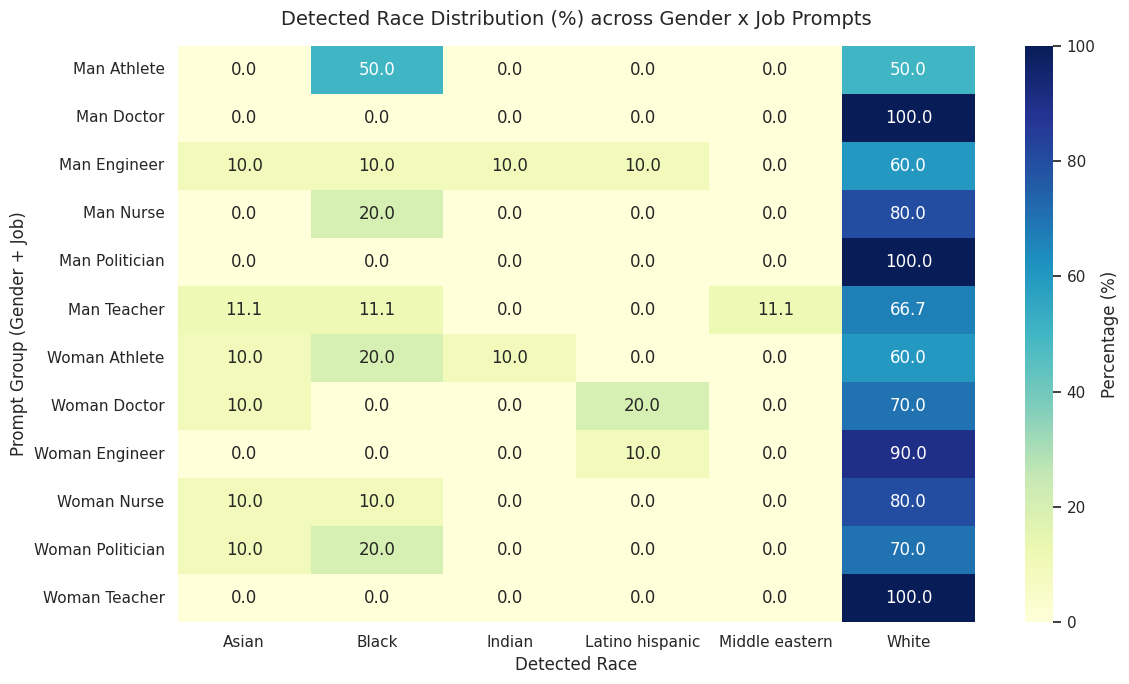

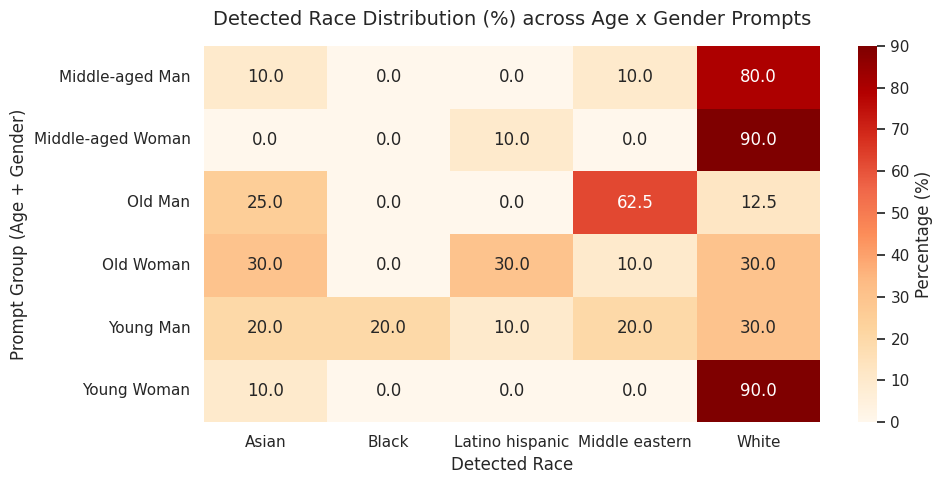

In [ ]:
# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# 1. Visualization for Gender x Job intersectional race bias
if not df_gender_job_race.empty:
    # Create a unique group identifier
    df_gender_job_race['Prompt_Group'] = df_gender_job_race['Prompt_Gender'] + " " + df_gender_job_race['Prompt_Job']

    # Calculate percentage distribution of races within each Prompt Group
    df_pivot_gj = df_gender_job_race.groupby(['Prompt_Group', 'Detected_Race']).size().unstack(fill_value=0)
    df_pivot_gj_pct = df_pivot_gj.div(df_pivot_gj.sum(axis=1), axis=0) * 100

    plt.figure(figsize=(12, 7))
    sns.heatmap(df_pivot_gj_pct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Percentage (%)'})
    plt.title('Detected Race Distribution (%) across Gender x Job Prompts', fontsize=14, pad=15)
    plt.ylabel('Prompt Group (Gender + Job)')
    plt.xlabel('Detected Race')
    plt.tight_layout()
    plt.show()
else:
    print("No data available for Gender x Job intersection.")

# 2. Visualization for Age x Gender intersectional race bias
if not df_age_gender_race.empty:
    # Create a unique group identifier
    df_age_gender_race['Prompt_Group'] = df_age_gender_race['Prompt_Age'] + " " + df_age_gender_race['Prompt_Gender']

    # Calculate percentage distribution of races within each Prompt Group
    df_pivot_ag = df_age_gender_race.groupby(['Prompt_Group', 'Detected_Race']).size().unstack(fill_value=0)
    df_pivot_ag_pct = df_pivot_ag.div(df_pivot_ag.sum(axis=1), axis=0) * 100

    plt.figure(figsize=(10, 5))
    sns.heatmap(df_pivot_ag_pct, annot=True, fmt=".1f", cmap="OrRd", cbar_kws={'label': 'Percentage (%)'})
    plt.title('Detected Race Distribution (%) across Age x Gender Prompts', fontsize=14, pad=15)
    plt.ylabel('Prompt Group (Age + Gender)')
    plt.xlabel('Detected Race')
    plt.tight_layout()
    plt.show()
else:
    print("No data available for Age x Gender intersection.")

#### Age bias

In [ ]:
# Define the lists of target categories
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'athlete', 'politician']
genders = ['female', 'male']
genders_noun = ['woman', 'man']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']

# Initialize lists to collect age data for each combination type
gender_job_age_data = []
race_job_age_data = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Extract detected age from facial features if available and valid
            detected_age = None
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    detected_age = data['facial_feats'][0].get('age')

            if detected_age is not None:
                # 1. Check for prompt-specified Gender x Job combinations
                matched_gender = next((g for g in genders + genders_noun if g in prompt), None)
                matched_job = next((j for j in jobs if j in prompt), None)

                if matched_gender and matched_job:
                    # Standardize gender string representation
                    gender_label = 'Woman' if matched_gender in ['female', 'woman'] else 'Man'
                    gender_job_age_data.append({
                        'Prompt_Gender': gender_label,
                        'Prompt_Job': matched_job.capitalize(),
                        'Detected_Age': detected_age
                    })

                # 2. Check for prompt-specified Race x Job combinations
                matched_race = next((r for r in races if r in prompt), None)

                if matched_race and matched_job:
                    race_job_age_data.append({
                        'Prompt_Race': matched_race.capitalize(),
                        'Prompt_Job': matched_job.capitalize(),
                        'Detected_Age': detected_age
                    })

# Convert collected data lists into DataFrames
df_gender_job_age = pd.DataFrame(gender_job_age_data)
df_race_job_age = pd.DataFrame(race_job_age_data)

print(f"Collected {len(df_gender_job_age)} records for gender x job intersectional age analysis.")
print(f"Collected {len(df_race_job_age)} records for race x job intersectional age analysis.")

Collected 114 records for gender x job intersectional age analysis.
Collected 295 records for race x job intersectional age analysis.


/tmp/ipykernel_2757/3602957069.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_gender_job_age, x='Prompt_Group', y='Detected_Age', palette='Set2')


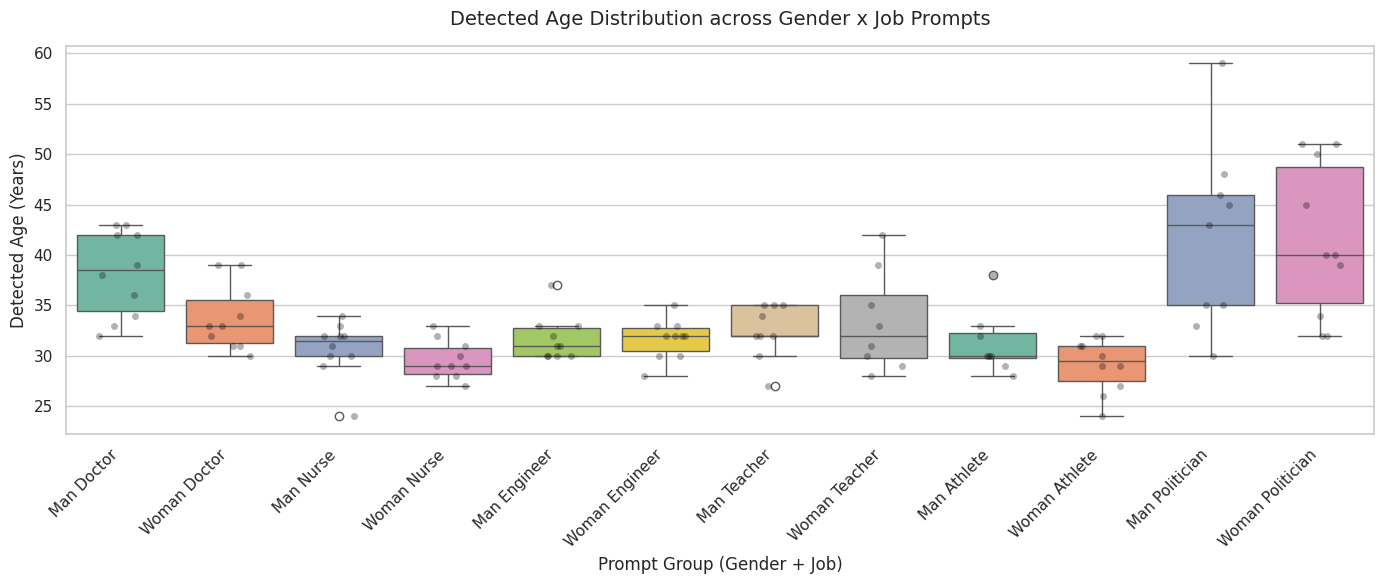

/tmp/ipykernel_2757/3602957069.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_race_job_age, x='Prompt_Group', y='Detected_Age', palette='Set3')


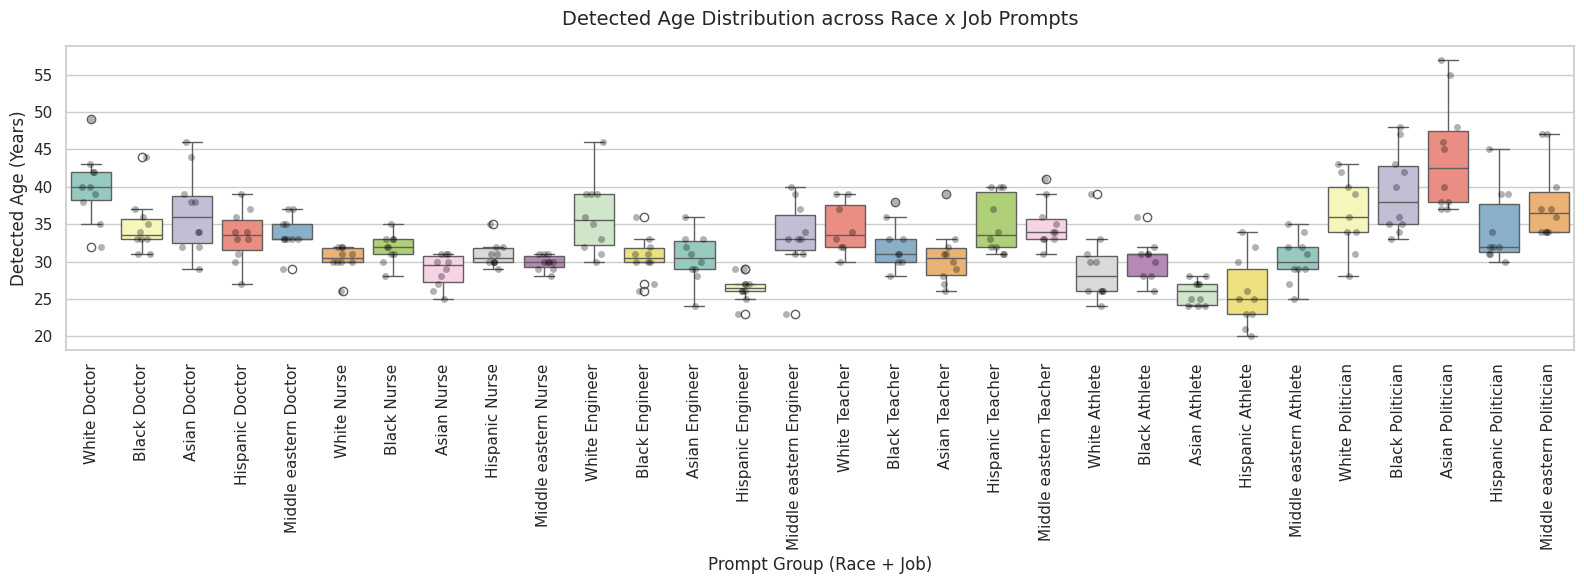

In [ ]:
sns.set_theme(style="whitegrid")

# 1. Visualization for Gender x Job vs. Detected Age
if not df_gender_job_age.empty:
    df_gender_job_age['Prompt_Group'] = df_gender_job_age['Prompt_Gender'] + " " + df_gender_job_age['Prompt_Job']

    plt.figure(figsize=(14, 6))
    sns.boxplot(data=df_gender_job_age, x='Prompt_Group', y='Detected_Age', palette='Set2')
    sns.stripplot(data=df_gender_job_age, x='Prompt_Group', y='Detected_Age', color='black', alpha=0.3, jitter=0.2)
    plt.title('Detected Age Distribution across Gender x Job Prompts', fontsize=14, pad=15)
    plt.ylabel('Detected Age (Years)')
    plt.xlabel('Prompt Group (Gender + Job)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No data available for Gender x Job age intersection.")

# 2. Visualization for Race x Job vs. Detected Age
if not df_race_job_age.empty:
    df_race_job_age['Prompt_Group'] = df_race_job_age['Prompt_Race'] + " " + df_race_job_age['Prompt_Job']

    plt.figure(figsize=(16, 6))
    sns.boxplot(data=df_race_job_age, x='Prompt_Group', y='Detected_Age', palette='Set3')
    sns.stripplot(data=df_race_job_age, x='Prompt_Group', y='Detected_Age', color='black', alpha=0.3, jitter=0.2)
    plt.title('Detected Age Distribution across Race x Job Prompts', fontsize=14, pad=15)
    plt.ylabel('Detected Age (Years)')
    plt.xlabel('Prompt Group (Race + Job)')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print("No data available for Race x Job age intersection.")

#### Emotional bias

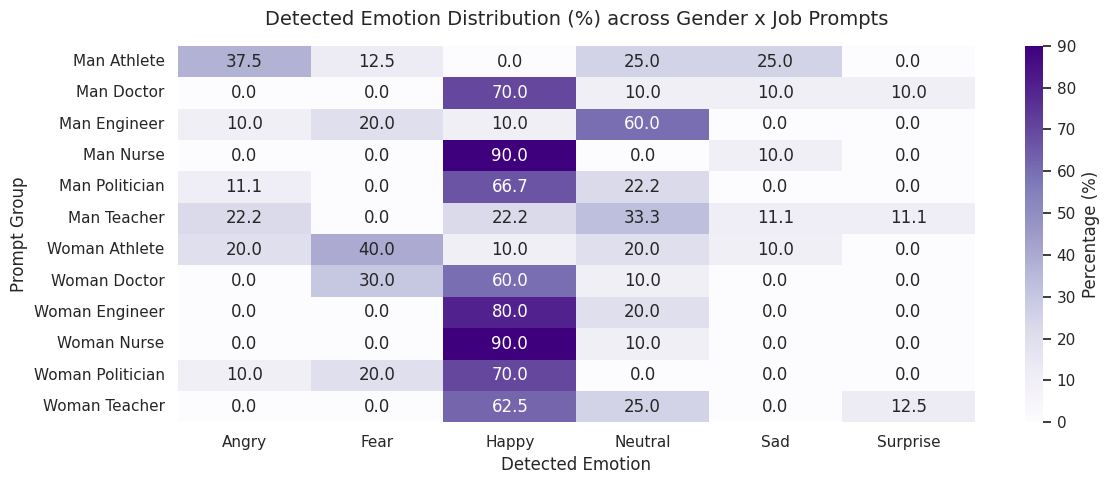

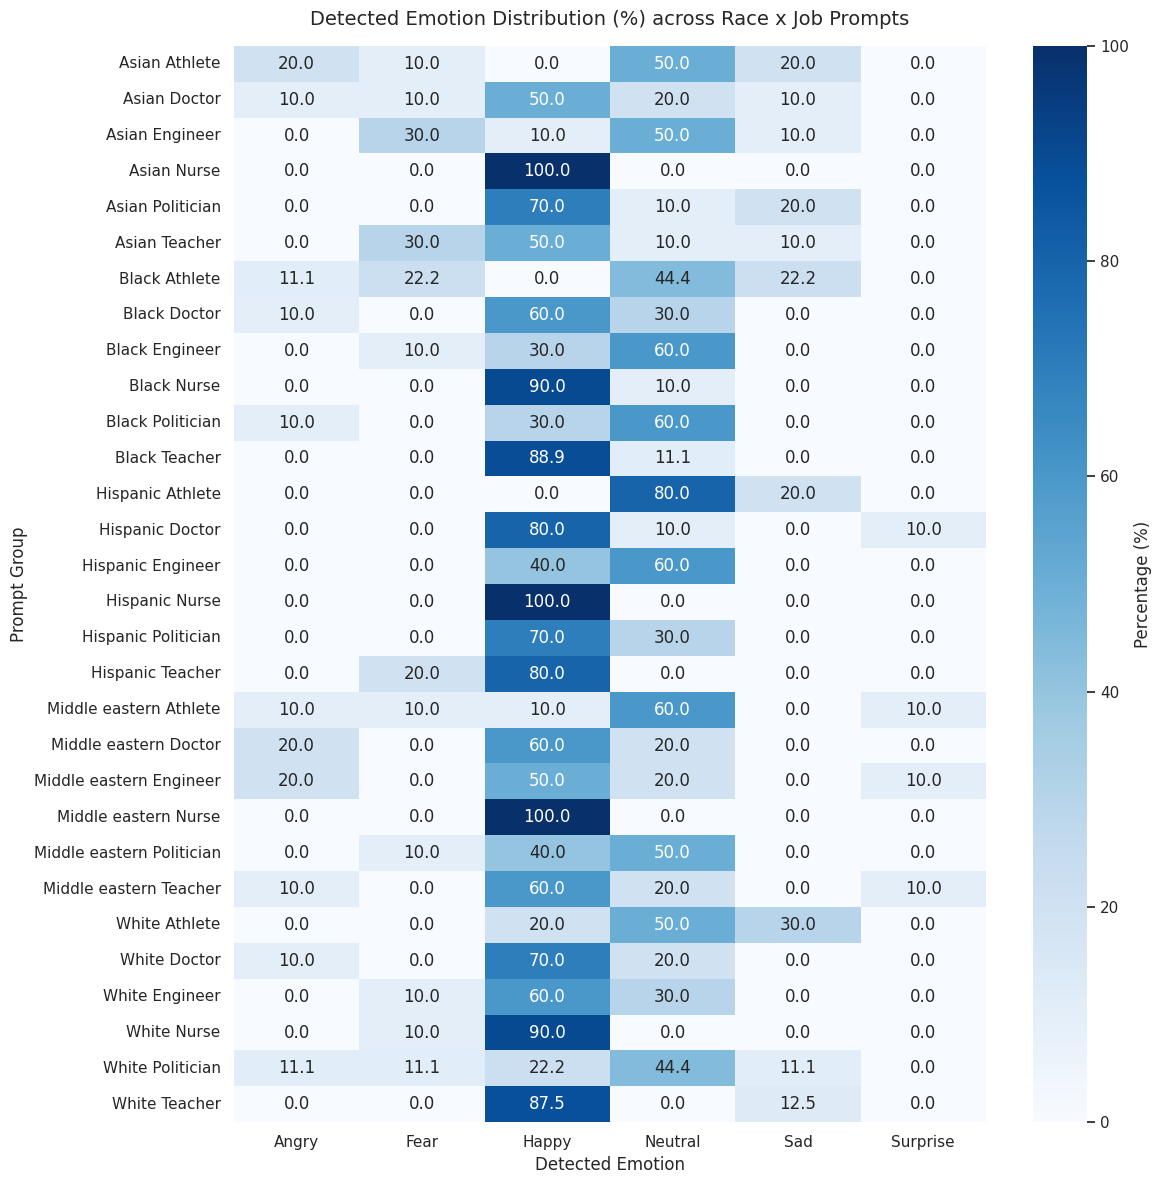

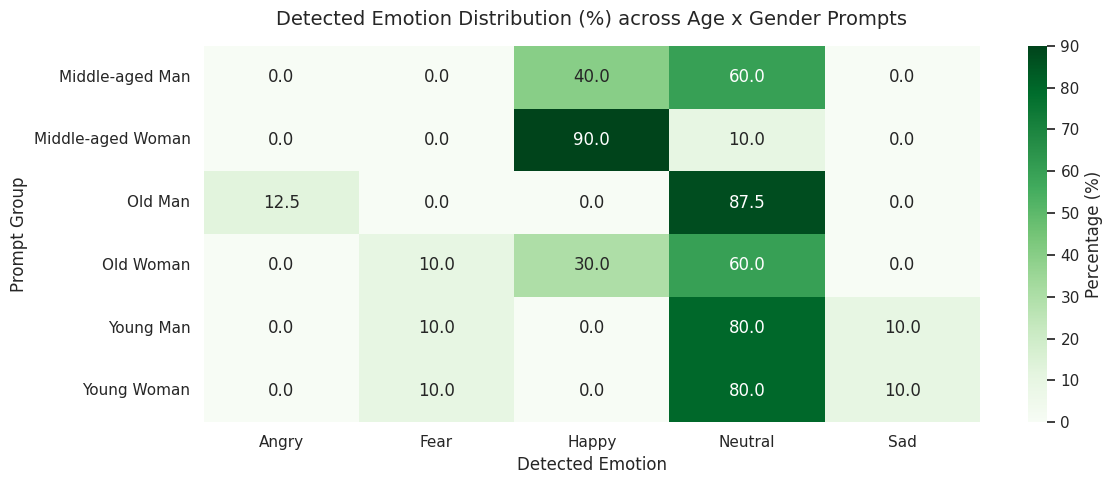

In [ ]:
# Define categories
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'athlete', 'politician']
genders = ['female', 'male']
genders_noun = ['woman', 'man']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern']
ages = ['young', 'old', 'middle-aged']

# Initialize lists to collect data
gender_job_emotion = []
race_job_emotion = []
age_gender_emotion = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                data = json.load(fr)

            prompt = data.get('prompt', '').lower()

            # Extract detected emotion if available and valid
            detected_emotion = None
            if 'facial_feats' in data and len(data['facial_feats']) > 0:
                if data['facial_feats'][0].get('face_confidence', -1) != -1:
                    detected_emotion = data['facial_feats'][0].get('dominant_emotion')

            if detected_emotion:
                detected_emotion = detected_emotion.capitalize()
                matched_gender = next((g for g in genders + genders_noun if g in prompt), None)
                matched_job = next((j for j in jobs if j in prompt), None)
                matched_race = next((r for r in races if r in prompt), None)
                matched_age = next((a for a in ages if a in prompt), None)

                gender_label = 'Woman' if matched_gender in ['female', 'woman'] else 'Man' if matched_gender else None

                # 1. Gender x Job
                if gender_label and matched_job:
                    gender_job_emotion.append({
                        'Prompt_Group': f"{gender_label} {matched_job.capitalize()}",
                        'Detected_Emotion': detected_emotion
                    })

                # 2. Race x Job
                if matched_race and matched_job:
                    race_job_emotion.append({
                        'Prompt_Group': f"{matched_race.capitalize()} {matched_job.capitalize()}",
                        'Detected_Emotion': detected_emotion
                    })

                # 3. Age x Gender
                if matched_age and gender_label:
                    age_gender_emotion.append({
                        'Prompt_Group': f"{matched_age.capitalize()} {gender_label}",
                        'Detected_Emotion': detected_emotion
                    })

# Create DataFrames
df_gj_emotion = pd.DataFrame(gender_job_emotion)
df_rj_emotion = pd.DataFrame(race_job_emotion)
df_ag_emotion = pd.DataFrame(age_gender_emotion)

# Helper function to plot heatmap of percentage distributions
def plot_emotion_heatmap(df, title, cmap):
    if not df.empty:
        pivot = df.groupby(['Prompt_Group', 'Detected_Emotion']).size().unstack(fill_value=0)
        pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

        plt.figure(figsize=(12, max(5, len(pivot_pct) * 0.4)))
        sns.heatmap(pivot_pct, annot=True, fmt=".1f", cmap=cmap, cbar_kws={'label': 'Percentage (%)'})
        plt.title(title, fontsize=14, pad=15)
        plt.ylabel('Prompt Group')
        plt.xlabel('Detected Emotion')
        plt.tight_layout()
        plt.show()
    else:
        print(f"No data available for: {title}")

sns.set_theme(style="whitegrid")

# Plot the heatmaps
plot_emotion_heatmap(df_gj_emotion, 'Detected Emotion Distribution (%) across Gender x Job Prompts', 'Purples')
plot_emotion_heatmap(df_rj_emotion, 'Detected Emotion Distribution (%) across Race x Job Prompts', 'Blues')
plot_emotion_heatmap(df_ag_emotion, 'Detected Emotion Distribution (%) across Age x Gender Prompts', 'Greens')

## ?

In [ ]:
# Define vocabulary to search in prompts
genders = ['female', 'male', 'woman', 'man']
races = ['white', 'black', 'asian', 'hispanic', 'middle eastern', 'latino']
ages = ['young', 'old', 'middle-aged']
jobs = ['doctor', 'nurse', 'engineer', 'teacher', 'athlete', 'politician', 'artist', 'scientist', 'chef', 'pilot', 'writer', 'musician', 'soldier']

data_records = []

for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                img_data = json.load(fr)

            prompt = img_data.get('prompt', '').lower()

            # Extract prompt specifications
            p_gender = None
            if 'female' in prompt or 'woman' in prompt:
                p_gender = 'female'
            elif 'male' in prompt or 'man' in prompt:
                p_gender = 'male'

            p_race = next((r for r in races if r in prompt), None)
            if p_race == 'latino':
                p_race = 'hispanic'

            p_age = next((a for a in ages if a in prompt), None)
            p_job = next((j for j in jobs if j in prompt), None)

            # Extract output features (from valid face detections)
            o_gender = None
            o_race = None
            o_age = None
            o_emotion = None

            if 'facial_feats' in img_data and len(img_data['facial_feats']) > 0:
                feat = img_data['facial_feats'][0]
                if feat.get('face_confidence', -1) != -1:
                    o_gender = feat.get('dominant_gender')
                    o_race = feat.get('dominant_race')
                    o_age = feat.get('age')
                    o_emotion = feat.get('dominant_emotion')

            data_records.append({
                'prompt_gender': p_gender,
                'prompt_race': p_race,
                'prompt_age': p_age,
                'prompt_job': p_job,
                'output_gender': o_gender,
                'output_race': o_race,
                'output_age': o_age,
                'output_emotion': o_emotion
            })

df_bias = pd.DataFrame(data_records)
print(f"DataFrame constructed with {len(df_bias)} rows.")
df_bias.head(10)

DataFrame constructed with 480 rows.


,prompt_gender,prompt_race,prompt_age,prompt_job,output_gender,output_race,output_age,output_emotion
0,male,None,None,doctor,Man,white,33.0,happy
1,male,None,None,doctor,Man,white,38.0,surprise
2,male,None,None,doctor,Man,white,34.0,sad
3,male,None,None,doctor,Man,white,36.0,happy
4,male,None,None,doctor,Man,white,42.0,neutral
5,male,None,None,doctor,Man,white,43.0,happy
6,male,None,None,doctor,Man,white,42.0,happy
7,male,None,None,doctor,Man,white,43.0,happy
8,male,None,None,doctor,Man,white,39.0,happy
9,male,None,None,doctor,Man,white,32.0,happy


#### Intersectional analysis

emotions

In [ ]:
# Identify unique prompt combinations (by grouping prompt specifications) and calculate emotional percentages
prompt_cols = ['prompt_gender', 'prompt_race', 'prompt_age', 'prompt_job']

# Filter rows where a valid emotion was detected and use .copy() to avoid SettingWithCopyWarning
df_valid_emotions = df_bias.dropna(subset=['output_emotion']).copy()

# Create a multi-index representing the prompt combination, or join them as a single string
df_valid_emotions['prompt_combination'] = df_valid_emotions[prompt_cols].fillna('None').agg(' + '.join, axis=1)

# Calculate counts
emotion_counts = df_valid_emotions.groupby(['prompt_combination', 'output_emotion']).size().unstack(fill_value=0)

# Convert counts to percentages (row-wise normalized)
emotion_percentages = emotion_counts.div(emotion_counts.sum(axis=1), axis=0) * 100

# Format with a '%' sign for readability
emotion_percentage_formatted = emotion_percentages.map(lambda x: f"{x:.1f}%")

# Display the table
import IPython
display(IPython.display.HTML("<h3>Percentage of Images Showing a Certain Emotion for Each Prompt Combination</h3>"))
display(emotion_percentage_formatted)

NameError: name 'df_bias' is not defined

age

In [ ]:
# Identify unique prompt combinations and calculate mean, median, and SD for detected age
prompt_cols = ['prompt_gender', 'prompt_race', 'prompt_age', 'prompt_job']

# Filter rows with valid detected age
df_valid_age = df_bias.dropna(subset=['output_age']).copy()

# Join the prompt attributes to represent unique prompt combinations
df_valid_age['prompt_combination'] = df_valid_age[prompt_cols].fillna('None').agg(' + '.join, axis=1)

# Group and calculate mean, median, and standard deviation
age_stats = df_valid_age.groupby('prompt_combination')['output_age'].agg(['count', 'mean', 'median', 'std'])

# Rename columns for clarity
age_stats.columns = ['Count', 'Mean Age', 'Median Age', 'Age SD']

# Format the numerical columns for clean presentation
age_stats['Mean Age'] = age_stats['Mean Age'].map('{:.2f}'.format)
age_stats['Median Age'] = age_stats['Median Age'].map('{:.1f}'.format)
age_stats['Age SD'] = age_stats['Age SD'].map(lambda x: f"{x:.2f}" if pd.notnull(x) else "N/A")

# Display the table
import IPython
display(IPython.display.HTML("<h3>Age Statistics (Mean, Median, and SD) for Each Prompt Combination</h3>"))
display(age_stats)

,Count,Mean Age,Median Age,Age SD
prompt_combination,,,,
None + asian + None + athlete,10,25.90,26.0,1.66
None + asian + None + doctor,10,36.60,36.0,5.44
None + asian + None + engineer,10,30.50,30.5,3.31
None + asian + None + nurse,10,28.80,29.5,2.20
None + asian + None + politician,10,44.10,42.5,7.43
None + asian + None + teacher,10,30.60,30.5,3.69
None + black + None + athlete,9,30.33,31.0,2.87
None + black + None + doctor,10,34.70,33.5,3.80
None + black + None + engineer,10,30.60,30.5,2.84


#### Counterfactual analysis

from features

In [ ]:
# Re-construct df_bias to ensure it is defined in the current namespace
df_bias = pd.DataFrame(data_records)

# Filter for records that have both prompt_gender and prompt_job specified
df_cf = df_bias.dropna(subset=['prompt_gender', 'prompt_job', 'output_gender', 'output_age']).copy()

# Group by Job and compare the outputs when changing the prompt's specified Gender (Counterfactual)
# This measures the effect of changing specified gender (male vs female) while holding the job constant.
cf_analysis = df_cf.groupby(['prompt_job', 'prompt_gender']).agg(
    mean_detected_age=('output_age', 'mean'),
    pct_detected_female=('output_gender', lambda x: (x == 'Woman').mean() * 100),
    sample_count=('output_gender', 'count')
).unstack(level='prompt_gender')


cf_analysis.head(10)

mean_detected_age            pct_detected_female       \
prompt_gender            female       male              female male   
prompt_job                                                            
athlete                  29.100  31.250000                70.0  0.0   
doctor                   33.800  38.200000                90.0  0.0   
engineer                 31.700  31.700000                90.0  0.0   
nurse                    29.600  30.700000               100.0  0.0   
politician               41.400  41.555556               100.0  0.0   
teacher                  33.375  32.444444                87.5  0.0   

              sample_count       
prompt_gender       female male  
prompt_job                       
athlete                 10    8  
doctor                  10   10  
engineer                10   10  
nurse                   10   10  
politician              10    9  
teacher                  8    9

In [ ]:
# Filter for records that have both prompt_gender and prompt_job, and a valid detected emotion
df_cf_emotions = df_bias.dropna(subset=['prompt_gender', 'prompt_job', 'output_emotion']).copy()

# Count emotions per job and prompt gender combination
emotion_cf = df_cf_emotions.groupby(['prompt_job', 'prompt_gender', 'output_emotion']).size().unstack(fill_value=0)

# Convert counts to percentages (row-wise normalized within each job + prompt_gender cohort)
emotion_cf_pct = emotion_cf.div(emotion_cf.sum(axis=1), axis=0) * 100

# Format the table
emotion_cf_pct_formatted = emotion_cf_pct.map(lambda x: f"{x:.1f}%")

import IPython
display(IPython.display.HTML("<h3>Counterfactual Emotion Distribution: Holding Job Fixed, Varying Prompt Gender</h3>"))
display(emotion_cf_pct_formatted)

output_emotion            angry   fear  happy neutral    sad surprise
prompt_job prompt_gender                                             
athlete    female         20.0%  40.0%  10.0%   20.0%  10.0%     0.0%
           male           37.5%  12.5%   0.0%   25.0%  25.0%     0.0%
doctor     female          0.0%  30.0%  60.0%   10.0%   0.0%     0.0%
           male            0.0%   0.0%  70.0%   10.0%  10.0%    10.0%
engineer   female          0.0%   0.0%  80.0%   20.0%   0.0%     0.0%
           male           10.0%  20.0%  10.0%   60.0%   0.0%     0.0%
nurse      female          0.0%   0.0%  90.0%   10.0%   0.0%     0.0%
           male            0.0%   0.0%  90.0%    0.0%  10.0%     0.0%
politician female         10.0%  20.0%  70.0%    0.0%   0.0%     0.0%
           male           11.1%   0.0%  66.7%   22.2%   0.0%     0.0%
teacher    female          0.0%   0.0%  62.5%   25.0%   0.0%    12.5%
           male           22.2%   0.0%  22.2%   33.3%  11.1%    11.1%

from embeddings

Loaded 467 embeddings with verified detected race and gender.


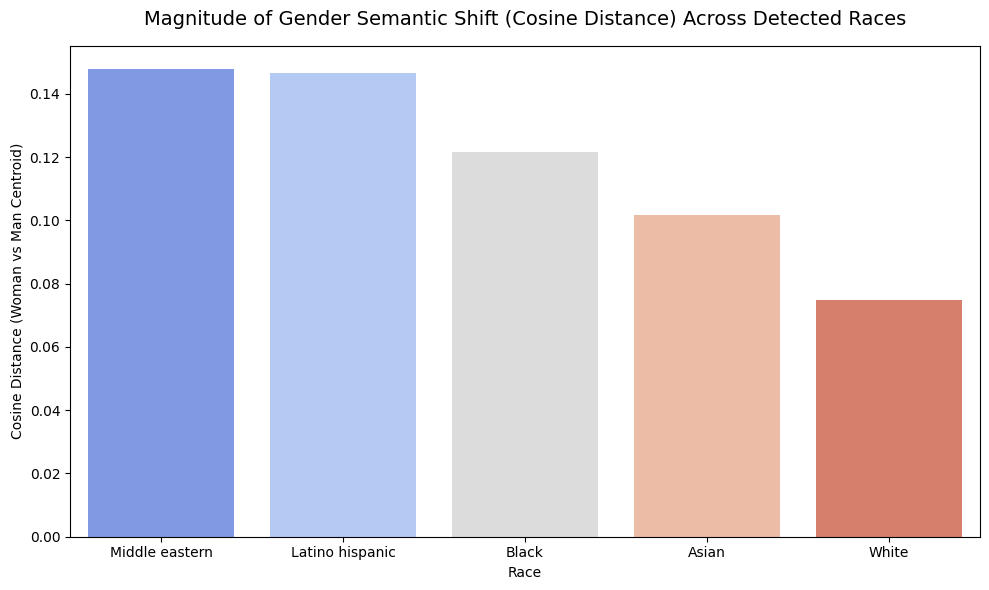


Magnitude of gender shift (Cosine Distance between Man & Woman Centroids) per Race:


,Race,Cosine Distance (Gender Shift),Female Samples,Male Samples
4,Middle eastern,0.147830,13,68
1,Latino hispanic,0.146623,12,26
3,Black,0.121769,18,62
2,Asian,0.101619,23,54
0,White,0.074730,68,116


In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

# Lists to compile our analysis dataset
embeddings_list = []
detected_races = []
detected_genders = []

# Retrieve and traverse directory to collect data
for path in os.listdir(dir):
    subdir_path = os.path.join(dir, path)
    if os.path.isdir(subdir_path):
        meta_file = os.path.join(subdir_path, 'meta.json')
        if os.path.exists(meta_file):
            with open(meta_file, 'r') as fr:
                img_data = json.load(fr)

            embedding = img_data.get('image_embedding', None)
            facial_feats = img_data.get('facial_feats', [])

            # Ensure we have a valid face detection and embedding
            if embedding is not None and len(facial_feats) > 0:
                feat = facial_feats[0]
                if feat.get('face_confidence', -1) != -1:
                    gender = feat.get('dominant_gender') # 'Man' or 'Woman'
                    race = feat.get('dominant_race')     # e.g. 'white', 'black', 'asian', etc.

                    if gender and race:
                        embeddings_list.append(np.array(embedding).flatten())
                        detected_races.append(race.lower())
                        detected_genders.append(gender.lower())

X_embs = np.array(embeddings_list)
df_embs = pd.DataFrame({
    'detected_race': detected_races,
    'detected_gender': detected_genders
})

print(f"Loaded {len(X_embs)} embeddings with verified detected race and gender.")

# Calculate centroid for each Race x Gender combination
unique_races = df_embs['detected_race'].unique()
results = []

for race in unique_races:
    # Female centroid
    idx_female = df_embs[(df_embs['detected_race'] == race) & (df_embs['detected_gender'] == 'woman')].index
    # Male centroid
    idx_male = df_embs[(df_embs['detected_race'] == race) & (df_embs['detected_gender'] == 'man')].index

    if len(idx_female) >= 3 and len(idx_male) >= 3: # Require a minimum of 3 samples for stable centroid
        centroid_female = X_embs[idx_female].mean(axis=0)
        centroid_male = X_embs[idx_male].mean(axis=0)

        # Compute Cosine Similarity and Cosine Distance
        sim = cosine_similarity(centroid_female.reshape(1, -1), centroid_male.reshape(1, -1))[0][0]
        dist = 1 - sim

        results.append({
            'Race': race.capitalize(),
            'Cosine Distance (Gender Shift)': dist,
            'Female Samples': len(idx_female),
            'Male Samples': len(idx_male)
        })

if results:
    df_shifts = pd.DataFrame(results).sort_values(by='Cosine Distance (Gender Shift)', ascending=False)

    # Visualize the shift across different races
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df_shifts, x='Race', y='Cosine Distance (Gender Shift)', palette='coolwarm', hue='Race', legend=False)
    plt.title('Magnitude of Gender Semantic Shift (Cosine Distance) Across Detected Races', fontsize=14, pad=15)
    plt.ylabel('Cosine Distance (Woman vs Man Centroid)')
    plt.xlabel('Race')
    plt.tight_layout()
    plt.show()

    print("\nMagnitude of gender shift (Cosine Distance between Man & Woman Centroids) per Race:")
    display(df_shifts)
else:
    print("Not enough samples to compute gender shift across intersectional groups.")